In [17]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import ndimage
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, roc_curve
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from celltype import features as ft, io_utils as io, models

CONFIG = r"C:\Users\sammxie\OneDrive - Boston University\Howelab\Code\Calcium_2p_preprocessing\python\celltype\config.yaml"
HOLDOUT = [r"Y:\2p_animals\mouse1\260928\932_3dir_rec000"]  # sessions to keep OUT of training so they are a fair test, e.g. [r"Y:\2p_animals\mouse1\261014\932_1dir_left_rec002"]
USE_BLOB = True           # the final models also get green_blob (stage 1) and red_blob (stage 2)
MODEL1 = "logreg"         # stage 1 classifier: "logreg" or "hgb" (boosted trees). Stage 2 is always logistic regression
N_REPEATS = 20            # permutations per feature and fold

cfg = io.load_config(CONFIG)
D = cfg["suite2p"]["diameter"]
TH = {1: (cfg["thresholds"]["p_spn_lo"], cfg["thresholds"]["p_spn_hi"]),
      2: (cfg["thresholds"]["p_red_lo"], cfg["thresholds"]["p_red_hi"])}

_blob_cache = {}
def blob_features(sdir):
    """Per ROI: strongest soma-shaped spot of the green / red image within half a diameter of its centre."""
    if sdir in _blob_cache:
        return _blob_cache[sdir]
    plane = io.load_plane(sdir); g, r = io.load_images(sdir, plane); stat = plane["stat"]
    rad = max(2, int(round(0.5 * D))); yy, xx = np.mgrid[-rad:rad + 1, -rad:rad + 1]; disc = yy ** 2 + xx ** 2 <= rad ** 2
    cy = np.array([s["ypix"].mean() for s in stat]).round().astype(int).clip(0, g.shape[0] - 1)
    cx = np.array([s["xpix"].mean() for s in stat]).round().astype(int).clip(0, g.shape[1] - 1)
    out = {"roi_idx": np.arange(len(stat))}
    for name, im in (("green_blob", g), ("red_blob", r)):
        out[name] = np.full(len(stat), np.nan) if im is None else \
            ndimage.maximum_filter(ft.blob_map(im, D), footprint=disc, mode="nearest")[cy, cx]
    _blob_cache[sdir] = pd.DataFrame(out)
    return _blob_cache[sdir]

def with_blobs(df):
    b = pd.concat([blob_features(s).assign(session_dir=s) for s in df["session_dir"].unique()], ignore_index=True)
    return df.merge(b, on=["session_dir", "roi_idx"], how="left")

ALL = with_blobs(models.training_table(cfg))                       # every ROI of every labeled session
hold_ids = {io.session_id(s, cfg["session_id_depth"]) for s in HOLDOUT}
DATA = ALL[~ALL.session_id.isin(hold_ids)].reset_index(drop=True)  # what the models are trained and cross-validated on
print(f"{DATA.session_id.nunique()} sessions, {DATA.animal.nunique()} animals; held out: {sorted(hold_ids) or 'none'}")
print("stage-1 labels:", DATA.stage1.value_counts().to_dict())
print("stage-2 labels among SPNs:", DATA[DATA.stage1 == "SPN"].stage2.value_counts().to_dict())

9 sessions, 1 animals; held out: ['mouse1/260928/932_3dir_rec000']
stage-1 labels: {'': 8228, 'SPN': 464, 'junk': 129, 'unsure': 77}
stage-2 labels among SPNs: {'red+': 232, 'red-': 161, 'ambiguous': 41, '': 30}


In [18]:
STAGE = {
    1: dict(name="Stage 1: SPN vs non-SPN", pos="SPN", neg="non-SPN", prob="p(SPN)",
            y=lambda d: np.where(d.stage1 == "SPN", 1, np.where(d.stage1.isin(models.NONSPN), 0, -1))),
    2: dict(name="Stage 2: red+ vs red-", pos="red+", neg="red-", prob="p(red)",
            y=lambda d: np.where((d.stage1 == "SPN") & (d.stage2 == "red+"), 1,
                                 np.where((d.stage1 == "SPN") & (d.stage2 == "red-"), 0, -1)))}
FEATS = {1: {"base": ft.MORPH + ft.ACTIVITY, "blob": ft.MORPH + ft.ACTIVITY + ["green_blob"]},
         2: {"base": list(ft.RED), "blob": list(ft.RED) + ["red_blob"]}}
GROUPS = {1: {"shape": ["eccentricity", "solidity", "aspect", "circularity", "s2p_compact"],
              "size": ["area_um2", "equiv_diam_um"],
              "nucleus / brightness": ["nucleus_shadow", "green_rel"],
              "event rate / amplitude": ["event_rate", "event_amp_med", "event_amp_cv", "frac_active"],
              "trace shape / noise": ["skew", "acf_1s", "acf_5s", "snr", "noise_sd"],
              "baseline": ["baseline_rel", "baseline_over_neuropil"],
              "green blob": ["green_blob"]},
          2: {"ring contrast": ["red_ring_ratio", "red_z", "red_fill", "red_mean_rel"],
              "core contrast": ["z_core", "z_coreB"],
              "spatial correlation": ["red_corr"],
              "red blob": ["red_blob"]}}

def make_model(which):
    if which == 1 and MODEL1 == "hgb":
        clf = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, class_weight="balanced")
    else:
        clf = LogisticRegression(class_weight="balanced", max_iter=2000)
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), clf)

def auc_drop(pipe, X, y, base, cols, rng, n):
    """Mean fall in AUC when the columns `cols` are shuffled together (rows permuted jointly)."""
    drops = []
    for _ in range(n):
        Xp = X.copy(); idx = rng.permutation(len(X))
        Xp[cols] = X[cols].to_numpy()[idx]
        drops.append(base - roc_auc_score(y, pipe.predict_proba(Xp)[:, 1]))
    return float(np.mean(drops))

def run_cv(which, cols, importance=False, seed=0):
    """Out-of-fold probabilities (each ROI predicted by a model that never saw its animal), per-held-out-group
    AUC, and (importance=True) permutation importance measured on the held-out data of each fold."""
    lab = STAGE[which]["y"](DATA); d = DATA[lab >= 0].reset_index(drop=True); y = lab[lab >= 0]
    g, scheme = d.animal.to_numpy(), "leave-one-animal-out"
    if len(set(g)) < 2:
        g, scheme = d.session_id.to_numpy(), "leave-one-session-out"
    splits = list(LeaveOneGroupOut().split(d, y, g)) if len(set(g)) >= 2 else \
        list(StratifiedKFold(5, shuffle=True, random_state=seed).split(d, y))
    if len(set(g)) < 2:
        scheme = "5-fold over ROIs (one session only: optimistic)"
    X = d[cols]; oof = np.full(len(d), np.nan); folds, imp_s, imp_g = [], {}, {}
    rng = np.random.default_rng(seed)
    for k, (tr, te) in enumerate(splits):
        if len(np.unique(y[tr])) < 2:
            continue
        pipe = make_model(which).fit(X.iloc[tr], y[tr]); p = pipe.predict_proba(X.iloc[te])[:, 1]; oof[te] = p
        name = str(g[te][0]) if scheme.startswith("leave") else f"fold {k + 1}"
        ok = len(np.unique(y[te])) == 2
        folds.append({"held out": name, "n": len(te), "n_pos": int(y[te].sum()), "n_neg": int((1 - y[te]).sum()),
                      "AUC": roc_auc_score(y[te], p) if ok else np.nan})
        if importance and ok:
            Xt, yt = X.iloc[te].reset_index(drop=True), y[te]; base = roc_auc_score(yt, p)
            imp_s[name] = pd.Series({c: auc_drop(pipe, Xt, yt, base, [c], rng, N_REPEATS) for c in cols})
            imp_g[name] = pd.Series({n: auc_drop(pipe, Xt, yt, base, [c for c in cs if c in cols], rng, N_REPEATS)
                                     for n, cs in GROUPS[which].items() if any(c in cols for c in cs)})
    return dict(d=d, y=y, oof=oof, scheme=scheme, folds=pd.DataFrame(folds), cols=cols, which=which,
                imp_s=pd.DataFrame(imp_s).T, imp_g=pd.DataFrame(imp_g).T)

def summary(res):
    """One row of numbers: ranking quality (AUC), and how the confident calls (the thresholds of the config) do."""
    lo, hi = TH[res["which"]]; y, p = res["y"], res["oof"]; m = ~np.isnan(p); y, p = y[m], p[m]
    pos, neg, conf = p >= hi, p <= lo, (p >= hi) | (p <= lo)
    return {"n": len(y), "n_pos": int(y.sum()), "n_neg": int((1 - y).sum()), "AUC (pooled)": roc_auc_score(y, p),
            "AUC mean over held-out groups": res["folds"]["AUC"].mean(),
            "balanced acc @0.5": balanced_accuracy_score(y, p >= 0.5),
            "confident calls (share of ROIs)": conf.mean(),
            "accuracy of confident calls": ((pos & (y == 1)) | (neg & (y == 0))).sum() / max(conf.sum(), 1),
            "pos called confidently": pos[y == 1].mean(), "neg called confidently": neg[y == 0].mean(),
            "confident mistakes": int((pos & (y == 0)).sum() + (neg & (y == 1)).sum())}

def abstain_confusion(y, p, lo, hi):
    """Rows: true neg / pos. Columns: confidently neg / not sure / confidently pos."""
    cols = np.where(p <= lo, 0, np.where(p >= hi, 2, 1))
    return np.array([[np.sum((y == t) & (cols == c)) for c in range(3)] for t in (0, 1)])

def plot_cv(res):
    which, spec = res["which"], STAGE[res["which"]]; lo, hi = TH[which]
    y, p, d = res["y"], res["oof"], res["d"]; m = ~np.isnan(p)
    fig, ax = plt.subplots(2, 3, figsize=(17, 9)); fig.suptitle(f"{spec['name']}: {res['scheme']}", fontsize=12)
    a = ax[0, 0]                                                       # ROC curves
    groups = d.animal if res["scheme"].startswith("leave-one-animal") else d.session_id
    for gname in pd.unique(groups[m]):
        s = (groups == gname).to_numpy() & m
        if len(np.unique(y[s])) == 2:
            fpr, tpr, _ = roc_curve(y[s], p[s]); a.plot(fpr, tpr, lw=1, alpha=.7, label=f"{gname} ({roc_auc_score(y[s], p[s]):.2f})")
    fpr, tpr, _ = roc_curve(y[m], p[m]); a.plot(fpr, tpr, "k", lw=2.5, label=f"all ({roc_auc_score(y[m], p[m]):.3f})")
    a.plot([0, 1], [0, 1], ":", color="gray"); a.set_xlabel("false positive rate"); a.set_ylabel("true positive rate")
    a.set_title("ROC of the held-out predictions"); a.legend(fontsize=7)
    a = ax[0, 1]                                                       # probability histograms
    bins = np.linspace(0, 1, 26)
    a.hist(p[m & (y == 0)], bins, alpha=.6, color="tab:blue", label=f"true {spec['neg']} ({int((y[m] == 0).sum())})")
    a.hist(p[m & (y == 1)], bins, alpha=.6, color="tab:red", label=f"true {spec['pos']} ({int((y[m] == 1).sum())})")
    for t in (lo, hi):
        a.axvline(t, color="k", ls="--", lw=1)
    a.set_xlabel(f"held-out {spec['prob']}"); a.set_title("dashed: the confident-call cutoffs of the config"); a.legend(fontsize=8)
    a = ax[0, 2]                                                       # confusion with 'not sure'
    cm = abstain_confusion(y[m], p[m], lo, hi); a.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(3):
            a.text(j, i, f"{cm[i, j]}\n{cm[i, j] / cm[i].sum():.0%}", ha="center", va="center", fontsize=10)
    a.set_xticks(range(3), [f"conf. {spec['neg']}", "not sure", f"conf. {spec['pos']}"], fontsize=8)
    a.set_yticks(range(2), [f"true {spec['neg']}", f"true {spec['pos']}"]); a.set_title("confusion with the 'not sure' band")
    a = ax[1, 0]                                                       # per held-out group AUC
    f = res["folds"].dropna(subset=["AUC"])
    a.barh(f["held out"], f["AUC"], color="tab:green"); a.axvline(.5, color="gray", ls=":"); a.set_xlim(.4, 1.0)
    for yy_, (au, n_, np_) in enumerate(zip(f["AUC"], f["n"], f["n_pos"])):
        a.text(.41, yy_, f"n={n_} (+{np_})", va="center", fontsize=7)
    a.set_xlabel("AUC on that held-out group"); a.set_title("does it hold up for every animal / session?")
    for a, key, ttl in ((ax[1, 1], "imp_s", "single features"), (ax[1, 2], "imp_g", "feature groups (shuffled together)")):
        imp = res[key]
        if imp.empty:
            a.axis("off"); a.text(0, .5, "run with importance=True", fontsize=9); continue
        mean, sd = imp.mean().sort_values(), imp.std().reindex(imp.mean().sort_values().index)
        a.barh(mean.index, mean.values, xerr=sd.values, color=["tab:red" if v > 0 else "0.6" for v in mean.values], ecolor="0.4")
        a.axvline(0, color="k", lw=.8); a.set_xlabel("fall in held-out AUC when shuffled (mean, SD over folds)")
        a.set_title(f"permutation importance: {ttl}"); a.tick_params(labelsize=7)
    plt.tight_layout(); plt.show()

def fit_final(which, cols):
    """The model for prediction: all labeled ROIs of the training sessions."""
    lab = STAGE[which]["y"](DATA); d = DATA[lab >= 0]
    return make_model(which).fit(d[cols], lab[lab >= 0])

def plot_coefficients(model, cols, title):
    clf = model.steps[-1][1]
    if not hasattr(clf, "coef_"):
        return
    w = pd.Series(clf.coef_[0], index=cols).sort_values()
    plt.figure(figsize=(7, .28 * len(w) + 1)); plt.barh(w.index, w.values, color=["tab:red" if v > 0 else "tab:blue" for v in w.values])
    plt.axvline(0, color="k", lw=.8); plt.title(f"{title}: weights (log-odds per SD)"); plt.tick_params(labelsize=7); plt.tight_layout(); plt.show()

leave-one-session-out: 593 labeled ROIs


,held out,n,n_pos,n_neg,AUC
0,mouse1/260925/932_GUI_rec000,12,10,2,1.000
1,mouse1/260929/932_3dir_rec000,58,43,15,0.981
2,mouse1/260929/932_3dir_rec001,1,1,0,NaN
3,mouse1/261012/932_1dir_left_rec002,27,24,3,0.903
4,mouse1/261013/932_3dir_rec000,25,25,0,NaN
5,mouse1/261013/932_3dir_rec001,20,14,6,0.702
6,mouse1/261014/932_1dir_left_rec001,263,222,41,0.989
7,mouse1/261014/932_1dir_left_rec002,103,99,4,0.985
8,mouse1/261020/932_3dir_rec000,84,26,58,0.973


,stage 1
n,593.000
n_pos,464.000
n_neg,129.000
AUC (pooled),0.953
AUC mean over held-out groups,0.933
balanced acc @0.5,0.903
confident calls (share of ROIs),0.806
accuracy of confident calls,0.958
pos called confidently,0.778
neg called confidently,0.752


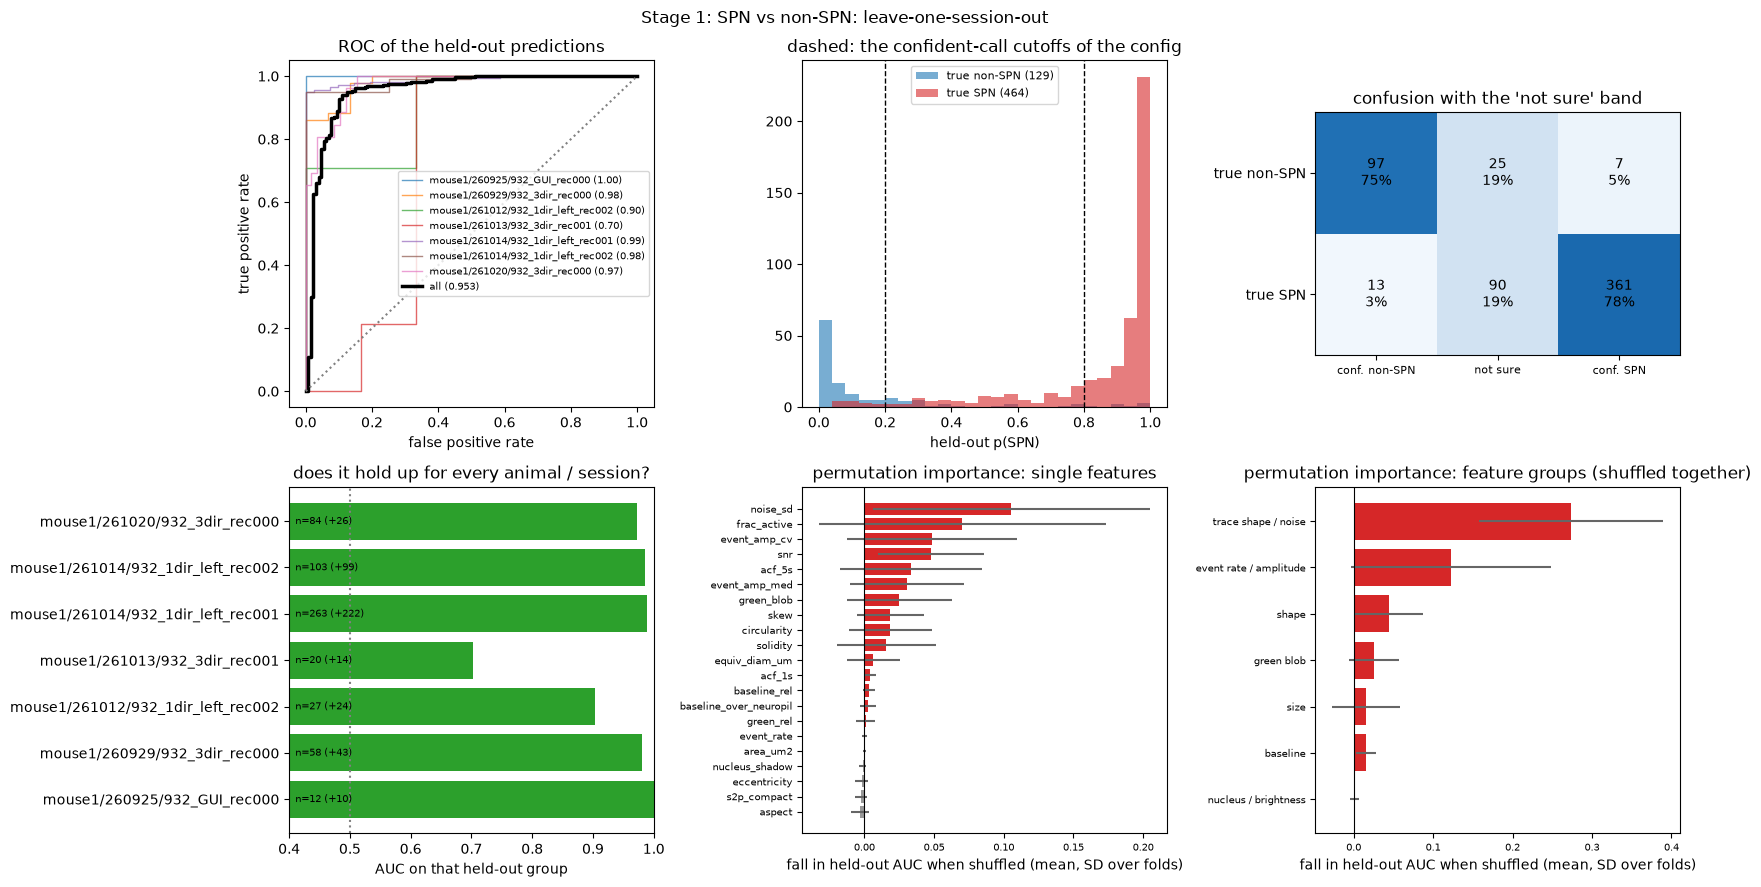

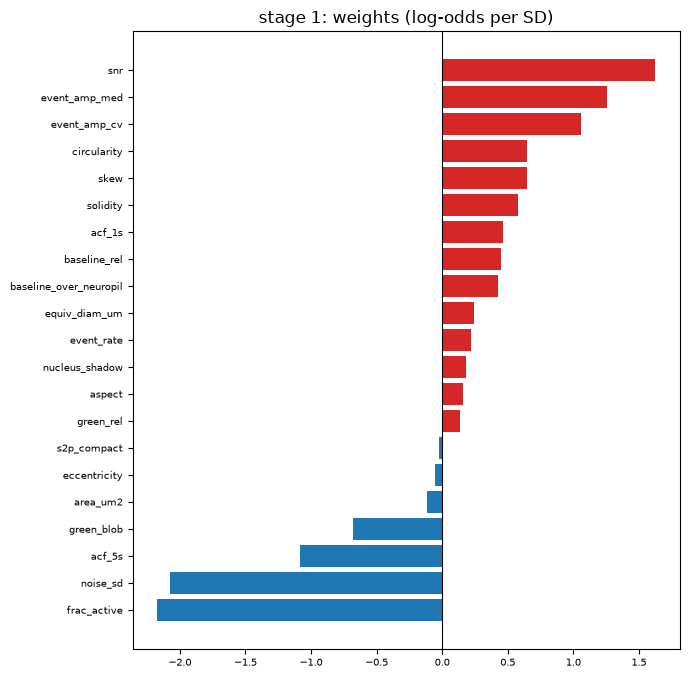

In [19]:
COLS1 = FEATS[1]["blob" if USE_BLOB else "base"]
res1 = run_cv(1, COLS1, importance=True)
print(f"{res1['scheme']}: {len(res1['y'])} labeled ROIs")
display(res1["folds"].round(3))
display(pd.Series(summary(res1)).round(3).to_frame("stage 1"))
plot_cv(res1)
M1 = fit_final(1, COLS1); plot_coefficients(M1, COLS1, "stage 1")

leave-one-session-out: 393 labeled SPNs


,held out,n,n_pos,n_neg,AUC
0,mouse1/260925/932_GUI_rec000,10,6,4,1.000
1,mouse1/260929/932_3dir_rec000,33,16,17,0.996
2,mouse1/260929/932_3dir_rec001,1,1,0,NaN
3,mouse1/261012/932_1dir_left_rec002,16,6,10,0.783
4,mouse1/261013/932_3dir_rec000,22,10,12,0.883
5,mouse1/261013/932_3dir_rec001,12,8,4,1.000
6,mouse1/261014/932_1dir_left_rec001,191,124,67,0.943
7,mouse1/261014/932_1dir_left_rec002,91,56,35,0.998
8,mouse1/261020/932_3dir_rec000,17,5,12,0.867


,stage 2
n,393.000
n_pos,232.000
n_neg,161.000
AUC (pooled),0.945
AUC mean over held-out groups,0.934
balanced acc @0.5,0.886
confident calls (share of ROIs),0.697
accuracy of confident calls,0.945
pos called confidently,0.625
neg called confidently,0.708


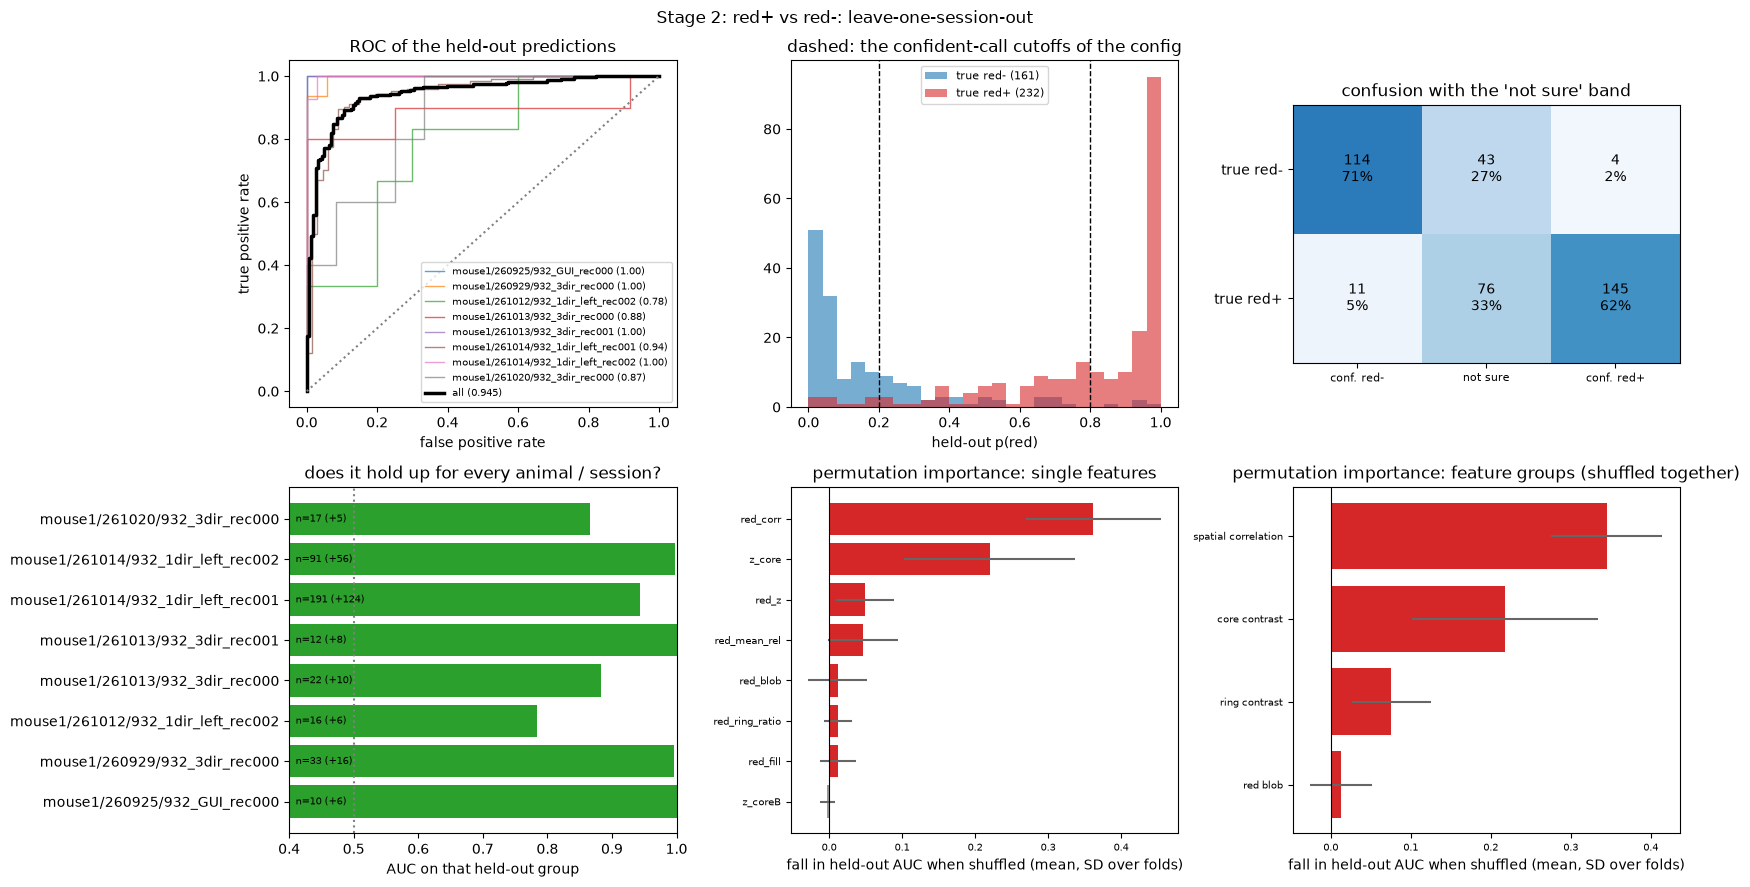

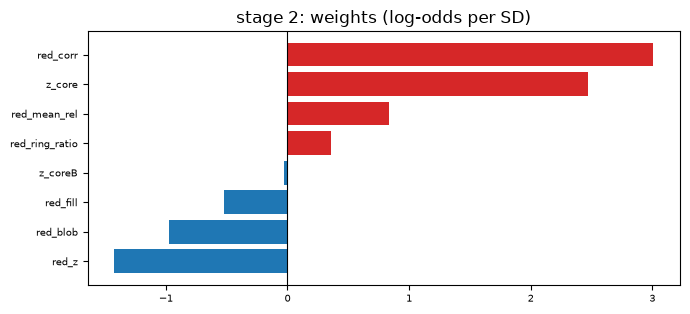

In [20]:
COLS2 = FEATS[2]["blob" if USE_BLOB else "base"]
res2 = run_cv(2, COLS2, importance=True)
print(f"{res2['scheme']}: {len(res2['y'])} labeled SPNs")
display(res2["folds"].round(3))
display(pd.Series(summary(res2)).round(3).to_frame("stage 2"))
plot_cv(res2)
M2 = fit_final(2, COLS2); plot_coefficients(M2, COLS2, "stage 2")

,stage,features,AUC (pooled),AUC mean over held-out groups,balanced acc @0.5,confident calls (share of ROIs),accuracy of confident calls,confident mistakes
0,1,base,0.951,0.927,0.900,0.818,0.959,20
1,1,blob (+ green blob),0.953,0.933,0.903,0.806,0.958,20
2,2,base,0.938,0.953,0.897,0.684,0.926,20
3,2,blob (+ red blob),0.945,0.934,0.886,0.697,0.945,15


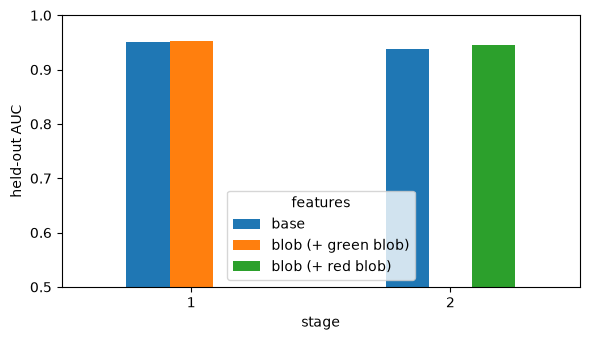

In [21]:
rows = []
for which in (1, 2):
    for name in ("base", "blob"):
        s = summary(run_cv(which, FEATS[which][name]))
        rows.append({"stage": which, "features": name + (" (+ green blob)" if which == 1 and name == "blob" else " (+ red blob)" if name == "blob" else ""),
                     **{k: s[k] for k in ("AUC (pooled)", "AUC mean over held-out groups", "balanced acc @0.5",
                                          "confident calls (share of ROIs)", "accuracy of confident calls", "confident mistakes")}})
cmp = pd.DataFrame(rows); display(cmp.round(3))
ax = cmp.pivot(index="stage", columns="features", values="AUC (pooled)").plot.bar(figsize=(6, 3.5), rot=0); ax.set_ylim(.5, 1); ax.set_ylabel("held-out AUC"); plt.tight_layout(); plt.show()

final_label
nonSPN           321
uncertain        270
iSPN             188
dSPN             125
SPN_ambiguous    113


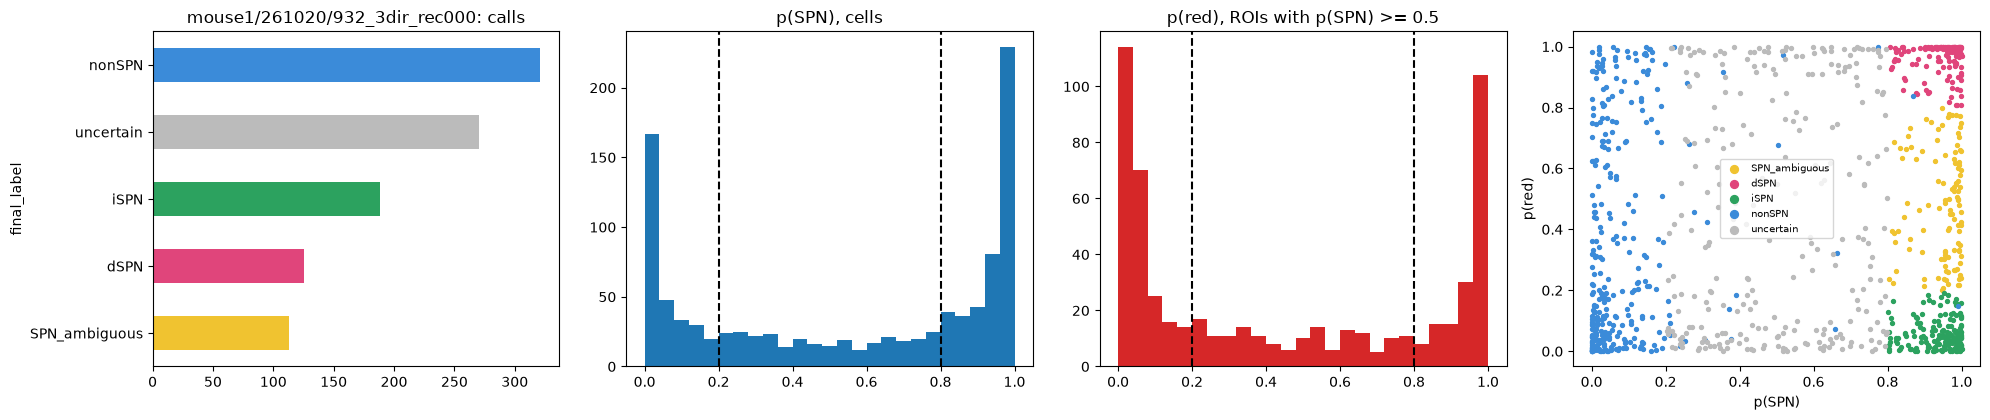

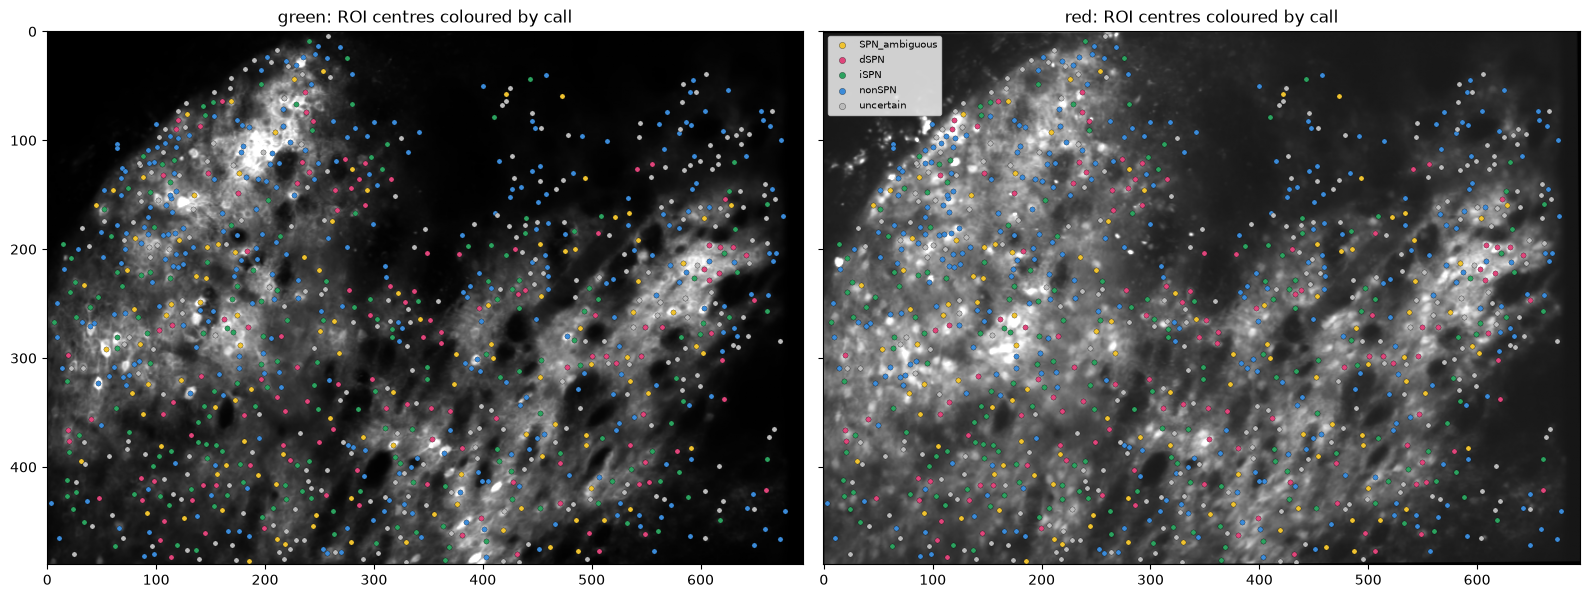

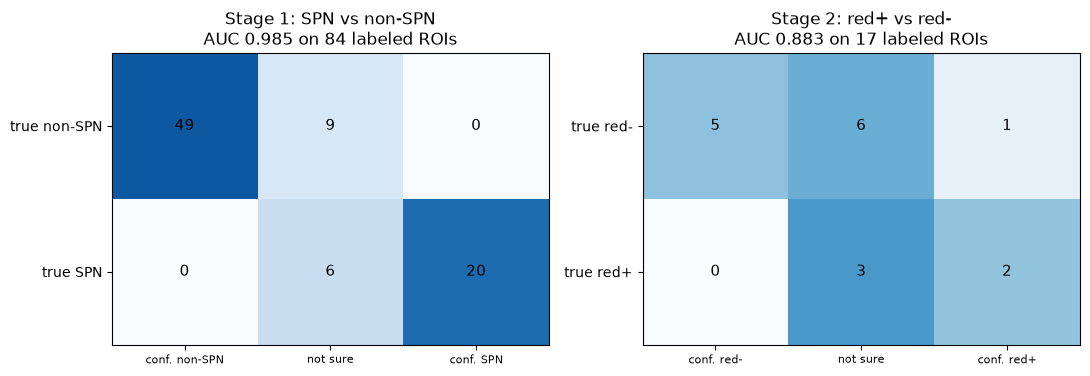

In [23]:
def load_session_table(sess):
    return with_blobs(ft.session_features(sess, cfg))

def call_labels(feat, p1, p2):
    th = cfg["thresholds"]; red_name, nored = ("dSPN", "iSPN") if cfg["cre_line"] == "D1" else ("iSPN", "dSPN")
    lab = np.where(p2 > th["p_red_hi"], red_name, np.where(p2 < th["p_red_lo"], nored, "SPN_ambiguous")).astype(object)
    rule = models.hard_rule_flag(feat, cfg)
    lab[p1 < th["p_spn_hi"]] = "uncertain"; lab[(p1 < th["p_spn_lo"]) | rule] = "nonSPN"
    if cfg["use_iscell"]:
        lab[feat["iscell"].to_numpy() == 0] = "not_cell"
    return lab, rule

def predict_session(sess, hand_only=True):
    sid = io.session_id(sess, cfg["session_id_depth"]); feat = load_session_table(sess)
    if sid in set(DATA.session_id):
        print(f"WARNING: {sid} is part of the training labels, so the numbers below are optimistic. "
              f"Put it in HOLDOUT (cell 1), rerun cells 1-4, then predict it.")
    p1 = M1.predict_proba(feat[COLS1])[:, 1]; p2 = M2.predict_proba(feat[COLS2])[:, 1]
    lab, rule = call_labels(feat, p1, p2)
    out = pd.DataFrame({"roi_idx": feat.roi_idx, "iscell": feat.iscell, "p_spn": p1, "p_red": p2, "hard_rule": rule, "final_label": lab})
    cnt = out[out.final_label != "not_cell"].final_label.value_counts(); print(cnt.to_string())
    fig, ax = plt.subplots(1, 4, figsize=(20, 4.3))
    cnt.sort_values().plot.barh(ax=ax[0], color=[models.COLORS.get(k, "gray") for k in cnt.sort_values().index]); ax[0].set_title(f"{sid}: calls")
    c = out.iscell == 1; ax[1].hist(p1[c], np.linspace(0, 1, 26), color="tab:blue"); ax[1].set_title("p(SPN), cells"); [ax[1].axvline(t, color="k", ls="--") for t in TH[1]]
    spn = c & (p1 >= .5); ax[2].hist(p2[spn], np.linspace(0, 1, 26), color="tab:red"); ax[2].set_title("p(red), ROIs with p(SPN) >= 0.5"); [ax[2].axvline(t, color="k", ls="--") for t in TH[2]]
    for k, v in out[c].groupby("final_label"):
        ax[3].scatter(v.p_spn, v.p_red, s=8, color=models.COLORS.get(k, "gray"), label=k)
    ax[3].set_xlabel("p(SPN)"); ax[3].set_ylabel("p(red)"); ax[3].legend(fontsize=7, markerscale=2); plt.tight_layout(); plt.show()
    try:                                                              # where the calls are in the image
        plane = io.load_plane(sess); g, r = io.load_images(sess, plane)
        fig, ax = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
        for a, im, t in ((ax[0], g, "green"), (ax[1], r if r is not None else g, "red")):
            a.imshow(im, cmap="gray", vmax=np.percentile(im, 99.7)); a.set_title(f"{t}: ROI centres coloured by call")
            for k, v in out[out.iscell == 1].groupby("final_label"):
                a.scatter(feat.cx[v.index], feat.cy[v.index], s=14, color=models.COLORS.get(k, "gray"), label=k, edgecolor="k", lw=.2)
        ax[1].legend(fontsize=7, markerscale=1.2); plt.tight_layout(); plt.show()
    except Exception as e:
        print("(image map skipped:", e, ")")
    la = io.load_labels(cfg["label_store"]); la = la[(la.session_id == sid) & (la.s2p_hash.astype(str) == str(feat.s2p_hash.iloc[0]))]
    if hand_only:
        la = la[la.source == "hand"]
    la = la.drop_duplicates("roi_idx", keep="last").set_index("roi_idx")
    if la.empty:
        print("no labels of this session in the label store: nothing to score against")
        return out
    ev = out.set_index("roi_idx").join(la[["stage1", "stage2"]], how="inner")
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for k, which in enumerate((1, 2)):
        yv = STAGE[which]["y"](ev); m = yv >= 0; col = "p_spn" if which == 1 else "p_red"
        if m.sum() < 3 or len(np.unique(yv[m])) < 2:
            ax[k].axis("off"); ax[k].text(0, .5, f"stage {which}: too few labels of both classes ({int(m.sum())})"); continue
        pv = ev[col].to_numpy()[m]; yv = yv[m]; lo, hi = TH[which]
        cm = abstain_confusion(yv, pv, lo, hi); spec = STAGE[which]
        ax[k].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
        for i in range(2):
            for j in range(3):
                ax[k].text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=11)
        ax[k].set_xticks(range(3), [f"conf. {spec['neg']}", "not sure", f"conf. {spec['pos']}"], fontsize=8)
        ax[k].set_yticks(range(2), [f"true {spec['neg']}", f"true {spec['pos']}"])
        ax[k].set_title(f"{spec['name']}\nAUC {roc_auc_score(yv, pv):.3f} on {len(yv)} labeled ROIs")
    plt.tight_layout(); plt.show()
    return out

pred_out = predict_session(r"Y:\2p_animals\mouse1\261020\932_3dir_rec000")

115 label rows for mouse1/261020/932_3dir_rec000
{'junk': 62, 'SPN': 33, 'unsure': 20}
{'junk/interneuron': 37, 'SPN': 33}
no values for: ['motion_noise_corr'] (no motion offsets in ops?)


,"AUC for SPN (0.5 = useless, <0.5: higher in junk)"
noise_sd,0.36
event_rate,0.43
frac_active,0.46
noise_tail_ratio,0.50
noise_cv,0.51
snr,0.56
noise_epoch_ratio,0.57
common_mode_corr,0.69
neuropil_corr,0.70
rise_decay_asym,0.82


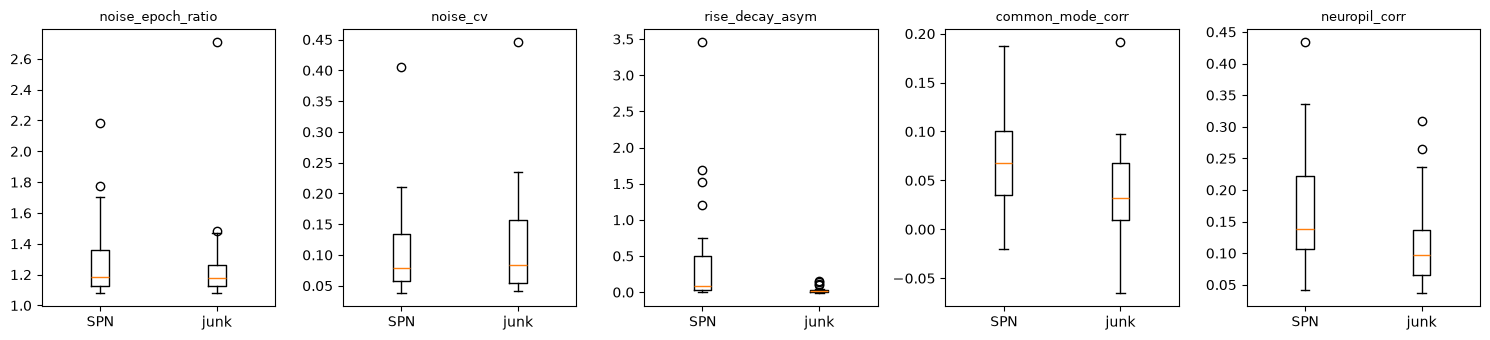

      roi_idx  noise_epoch_ratio  noise_cv  noise_tail_ratio  rise_decay_asym  \
711       711               3.01      0.51              1.42             0.03   
817       817               2.71      0.45              1.25             0.03   
902       902               2.51      0.34              1.16            -0.01   
997       997               2.39      0.38              1.24            -0.01   
1055     1055               2.33      0.28              1.10            -0.00   
566       566               2.23      0.30              1.10             0.04   
104       104               2.23      0.38              1.18             0.07   
1009     1009               2.22      0.22              1.05             0.01   
895       895               2.19      0.30              1.12            -0.01   
5           5               2.18      0.41              1.20             0.03   

      common_mode_corr  neuropil_corr  motion_noise_corr  iscell  
711               0.00           0.02    

In [27]:
from scipy import ndimage, stats
from sklearn.metrics import roc_auc_score

def trace_qc(dff, F, Fneu, fs, iscell, xoff=None, yoff=None, win_s=30):
    """Trace features aimed at motion-like noise and neuropil contamination (n ROIs x T frames in)."""
    n, T = dff.shape
    sm = max(3, int(round(2 * fs)))
    hp = dff - ndimage.uniform_filter1d(dff, size=sm, axis=1, mode="nearest")            # drop slow drift
    out = {}
    d = np.diff(dff, axis=1)                                                              # 1. is the noise level steady?
    w = max(10, int(win_s * fs)); nwin = max(1, (T - 1) // w)
    dw = d[:, :nwin * w].reshape(n, nwin, w)
    mad = 1.4826 * np.median(np.abs(dw - np.median(dw, axis=2, keepdims=True)), axis=2) / np.sqrt(2)
    out["noise_epoch_ratio"] = mad.max(1) / (np.median(mad, axis=1) + 1e-9)
    out["noise_cv"] = mad.std(1) / (mad.mean(1) + 1e-9)
    rob = 1.4826 * np.median(np.abs(d - np.median(d, axis=1, keepdims=True)), axis=1)    # 2. heavy tails
    out["noise_tail_ratio"] = d.std(1) / (rob + 1e-9)
    k = max(3, int(round(0.2 * fs)))                                                      # 3. transient shape
    out["rise_decay_asym"] = stats.skew(np.diff(ndimage.uniform_filter1d(dff, size=k, axis=1), axis=1), axis=1)
    z = lambda x: (x - x.mean(1, keepdims=True)) / (x.std(1, keepdims=True) + 1e-9)
    ref = np.median(hp[np.asarray(iscell) > 0], axis=0)                                  # 4. follows the population
    out["common_mode_corr"] = (z(hp) * z(ref[None])).mean(1)
    hpF = F - ndimage.uniform_filter1d(F, size=sm, axis=1, mode="nearest")               # 5. follows its neuropil
    hpN = Fneu - ndimage.uniform_filter1d(Fneu, size=sm, axis=1, mode="nearest")
    out["neuropil_corr"] = (z(hpF) * z(hpN)).mean(1)
    if xoff is not None and yoff is not None and len(xoff) == T:                         # 6. noise follows image motion
        mag = np.hypot(np.asarray(xoff) - np.median(xoff), np.asarray(yoff) - np.median(yoff))
        amp = ndimage.uniform_filter1d(np.abs(hp), size=max(3, int(round(fs))), axis=1)
        out["motion_noise_corr"] = (z(amp) * z(ndimage.uniform_filter1d(mag, size=max(3, int(round(fs))))[None])).mean(1)
    else:
        out["motion_noise_corr"] = np.full(n, np.nan)
    return pd.DataFrame(out)

fs = cfg["suite2p"]["fs"]; ops = plane["ops"]
dff, _ = ft.compute_dff(plane, cfg)
q = trace_qc(dff, plane["F"], plane["Fneu"], fs, plane["iscell"][:, 0], ops.get("xoff"), ops.get("yoff"))
q.insert(0, "roi_idx", np.arange(len(q)))

# against your labels of this session: SPN (1) vs junk / interneuron (0)
sess = r"Y:\2p_animals\mouse1\261020\932_3dir_rec000"       # <- the one session to test

plane = io.load_plane(sess); stat = plane["stat"]
green, red = io.load_images(sess, plane)
feat = ft.session_features(sess, cfg).sort_values("roi_idx").reset_index(drop=True)
fs = cfg["suite2p"]["fs"]; ops = plane["ops"]
dff, _ = ft.compute_dff(plane, cfg)

la = io.load_labels(cfg["label_store"])
la = la[(la.session_id == io.session_id(sess, cfg["session_id_depth"])) & (la.s2p_hash.astype(str) == str(plane["hash"]))]
print(len(la), "label rows for", io.session_id(sess, cfg["session_id_depth"]))
print(la.stage1.value_counts().to_dict())


la = io.load_labels(cfg["label_store"])
la = la[(la.session_id == io.session_id(sess, cfg["session_id_depth"])) & (la.s2p_hash.astype(str) == str(plane["hash"]))]
la = la.drop_duplicates("roi_idx", keep="last")
t = (feat[["roi_idx", "skew", "noise_sd", "event_rate", "snr", "frac_active"]].merge(q, on="roi_idx")
     .merge(la[["roi_idx", "stage1"]], on="roi_idx"))
t = t[t.stage1.isin(["SPN", "junk", "interneuron"])].assign(y=lambda d: (d.stage1 == "SPN").astype(int))
print(t.y.value_counts().rename({1: "SPN", 0: "junk/interneuron"}).to_dict())
feats = [c for c in t.columns if c not in ("roi_idx", "stage1", "y")]
empty = [c for c in feats if t[c].isna().all()]
if empty:
    print("no values for:", empty, "(no motion offsets in ops?)")
aucs = pd.Series({c: roc_auc_score(t.y, t[c].fillna(t[c].median())) for c in feats if c not in empty})
display(aucs.round(2).sort_values().to_frame("AUC for SPN (0.5 = useless, <0.5: higher in junk)"))

cols = [c for c in ["noise_epoch_ratio", "noise_cv", "rise_decay_asym", "common_mode_corr", "neuropil_corr", "motion_noise_corr"] if c not in empty]
fig, ax = plt.subplots(1, len(cols), figsize=(3 * len(cols), 3.5))
for a, c in zip(ax, cols):
    a.boxplot([t[t.y == 1][c].dropna(), t[t.y == 0][c].dropna()])
    a.set_xticks([1, 2], ["SPN", "junk"]); a.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

# the ROIs the model calls SPN but whose noise level is the most uneven (look at these in the GUI)
chk = q.merge(feat[["roi_idx", "iscell"]], on="roi_idx"); chk = chk[chk.iscell == 1]
print(chk.sort_values("noise_epoch_ratio", ascending=False).head(10).round(2))

In [28]:
from celltype import model_test as mt
mt.torch_status()          # version, GPU yes/no, CPU threads; says plainly if torch is missing

{'installed': True, 'version': '2.14.1+cpu', 'cuda': False, 'threads': 6, 'device': 'cpu'}


{'installed': True,
 'version': '2.14.1+cpu',
 'cuda': False,
 'threads': 6,
 'device': 'cpu'}

In [29]:
from celltype import model_test as mt
lab1, lab2 = mt.LABELS[1](DATA), mt.LABELS[2](DATA)
rows = DATA[(lab1 >= 0) | (lab2 >= 0)].reset_index(drop=True)
inputs = mt.build_inputs(rows, cfg)
print(inputs["img"].shape, inputs["trace"].shape)

(593, 5, 32, 32) (593, 1, 512)


  fold 1/9: held out mouse1/260925/932_GUI_rec000 (12 ROIs)


C:\Users\sammxie\OneDrive - Boston University\Howelab\Code\Calcium_2p_preprocessing\python\celltype\model_test.py:172: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  loss.backward(); opt.step(); total += float(loss) * len(idx)


      CNN: 581 ROIs, 25 epochs, final training loss 0.062
      CNN: 318 ROIs, 25 epochs, final training loss 0.024
      CNN: 425 ROIs, 25 epochs, final training loss 0.057
      CNN: 419 ROIs, 25 epochs, final training loss 0.008
  fold 2/9: held out mouse1/260929/932_3dir_rec000 (58 ROIs)
      CNN: 535 ROIs, 25 epochs, final training loss 0.039
      CNN: 272 ROIs, 25 epochs, final training loss 0.077
      CNN: 395 ROIs, 25 epochs, final training loss 0.064
      CNN: 403 ROIs, 25 epochs, final training loss 0.012
  fold 3/9: held out mouse1/260929/932_3dir_rec001 (1 ROIs)
      CNN: 592 ROIs, 25 epochs, final training loss 0.047
      CNN: 329 ROIs, 25 epochs, final training loss 0.050
      CNN: 425 ROIs, 25 epochs, final training loss 0.057
      CNN: 430 ROIs, 25 epochs, final training loss 0.013
  fold 4/9: held out mouse1/261012/932_1dir_left_rec002 (27 ROIs)
      CNN: 566 ROIs, 25 epochs, final training loss 0.053
      CNN: 303 ROIs, 25 epochs, final training loss 0.050
 

,AUC (pooled),balanced acc @0.5,confident calls (share),accuracy of confident calls,pos called confidently,neg called confidently,confident mistakes,AUC (mean over held-out groups)
features (logistic),0.953,0.903,0.806,0.958,0.778,0.752,20.0,0.933
CNN,0.936,0.865,0.853,0.911,0.765,0.822,45.0,0.936
stack: features + CNN,0.954,0.900,0.826,0.949,0.772,0.829,25.0,0.936
blend: mean of the two logits,0.957,0.902,0.833,0.949,0.784,0.814,25.0,0.939


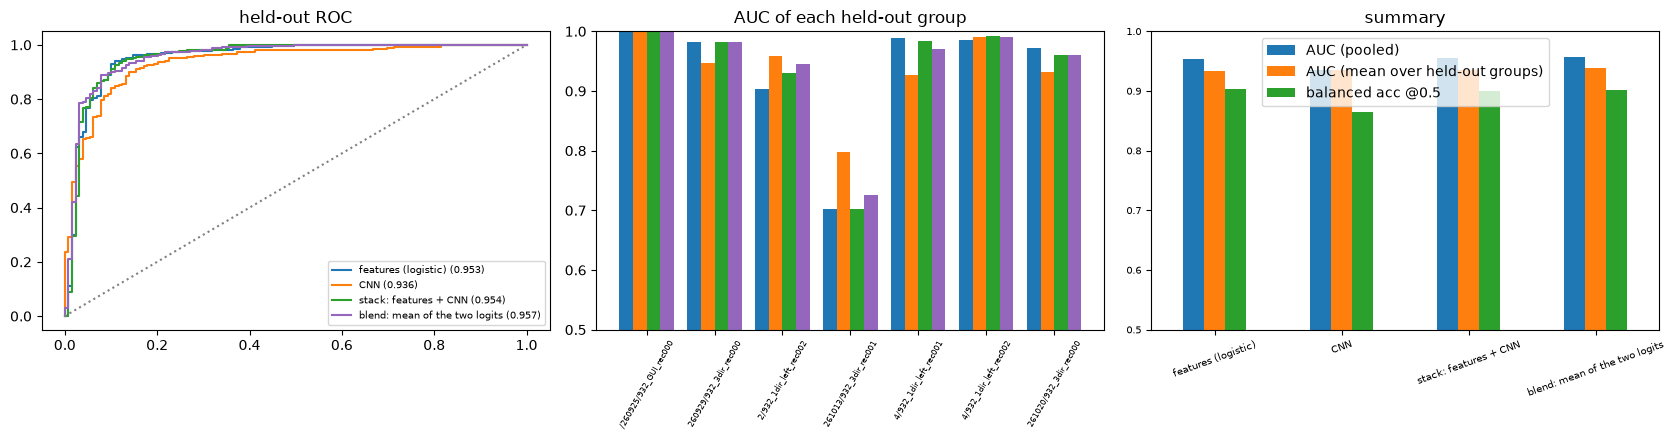

In [30]:
res1 = mt.compare(rows, inputs, which=1, cols=COLS1, cfg=cfg, epochs=25, inner_folds=3)   # , max_folds=2
mt.show(res1)

  fold 1/9: held out mouse1/260925/932_GUI_rec000 (10 ROIs)
      CNN: 383 ROIs, 30 epochs, final training loss 0.163
      CNN: 192 ROIs, 30 epochs, final training loss 0.151
      CNN: 291 ROIs, 30 epochs, final training loss 0.189
      CNN: 283 ROIs, 30 epochs, final training loss 0.115
  fold 2/9: held out mouse1/260929/932_3dir_rec000 (33 ROIs)
      CNN: 360 ROIs, 30 epochs, final training loss 0.142
      CNN: 169 ROIs, 30 epochs, final training loss 0.147
      CNN: 269 ROIs, 30 epochs, final training loss 0.209
      CNN: 282 ROIs, 30 epochs, final training loss 0.100
  fold 3/9: held out mouse1/260929/932_3dir_rec001 (1 ROIs)
      CNN: 392 ROIs, 30 epochs, final training loss 0.243
      CNN: 201 ROIs, 30 epochs, final training loss 0.221
      CNN: 291 ROIs, 30 epochs, final training loss 0.189
      CNN: 292 ROIs, 30 epochs, final training loss 0.106
  fold 4/9: held out mouse1/261012/932_1dir_left_rec002 (16 ROIs)
      CNN: 377 ROIs, 30 epochs, final training loss 0.209

,AUC (pooled),balanced acc @0.5,confident calls (share),accuracy of confident calls,pos called confidently,neg called confidently,confident mistakes,AUC (mean over held-out groups)
features (logistic),0.945,0.886,0.697,0.945,0.625,0.708,15.0,0.934
CNN,0.860,0.797,0.733,0.865,0.694,0.547,39.0,0.880
stack: features + CNN,0.946,0.888,0.697,0.949,0.612,0.733,14.0,0.934
blend: mean of the two logits,0.922,0.849,0.743,0.921,0.690,0.677,23.0,0.914


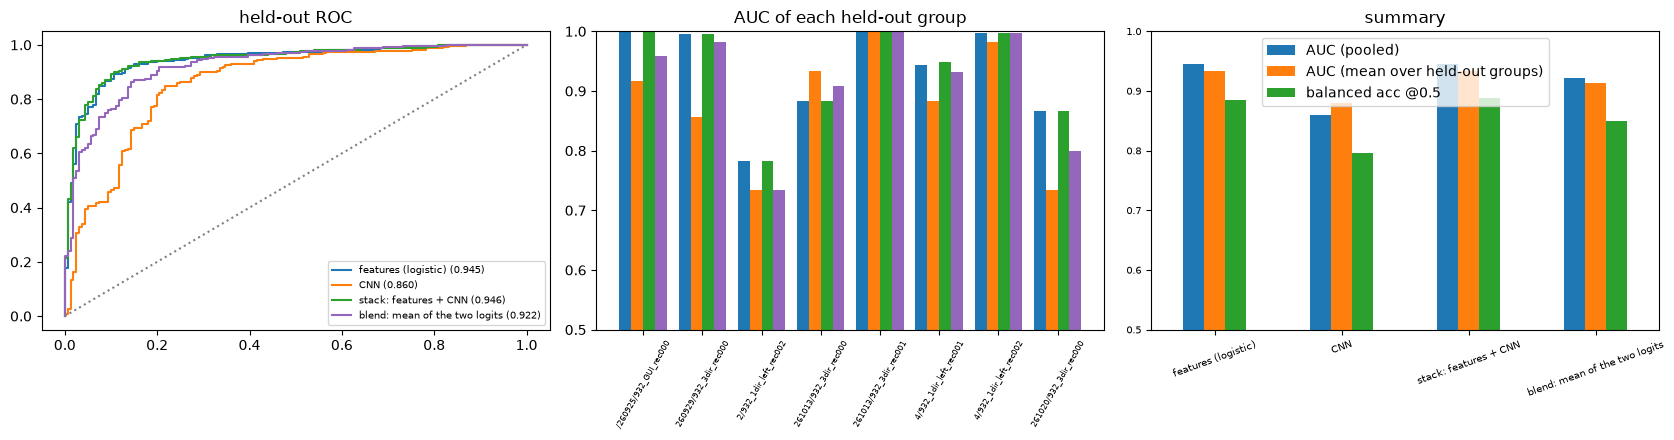

In [31]:
res2 = mt.compare(rows, inputs, which=2, cols=COLS2, cfg=cfg, epochs=30, inner_folds=3)   # , max_folds=2
mt.show(res2)

      CNN: 593 ROIs, 25 epochs, final training loss 0.045


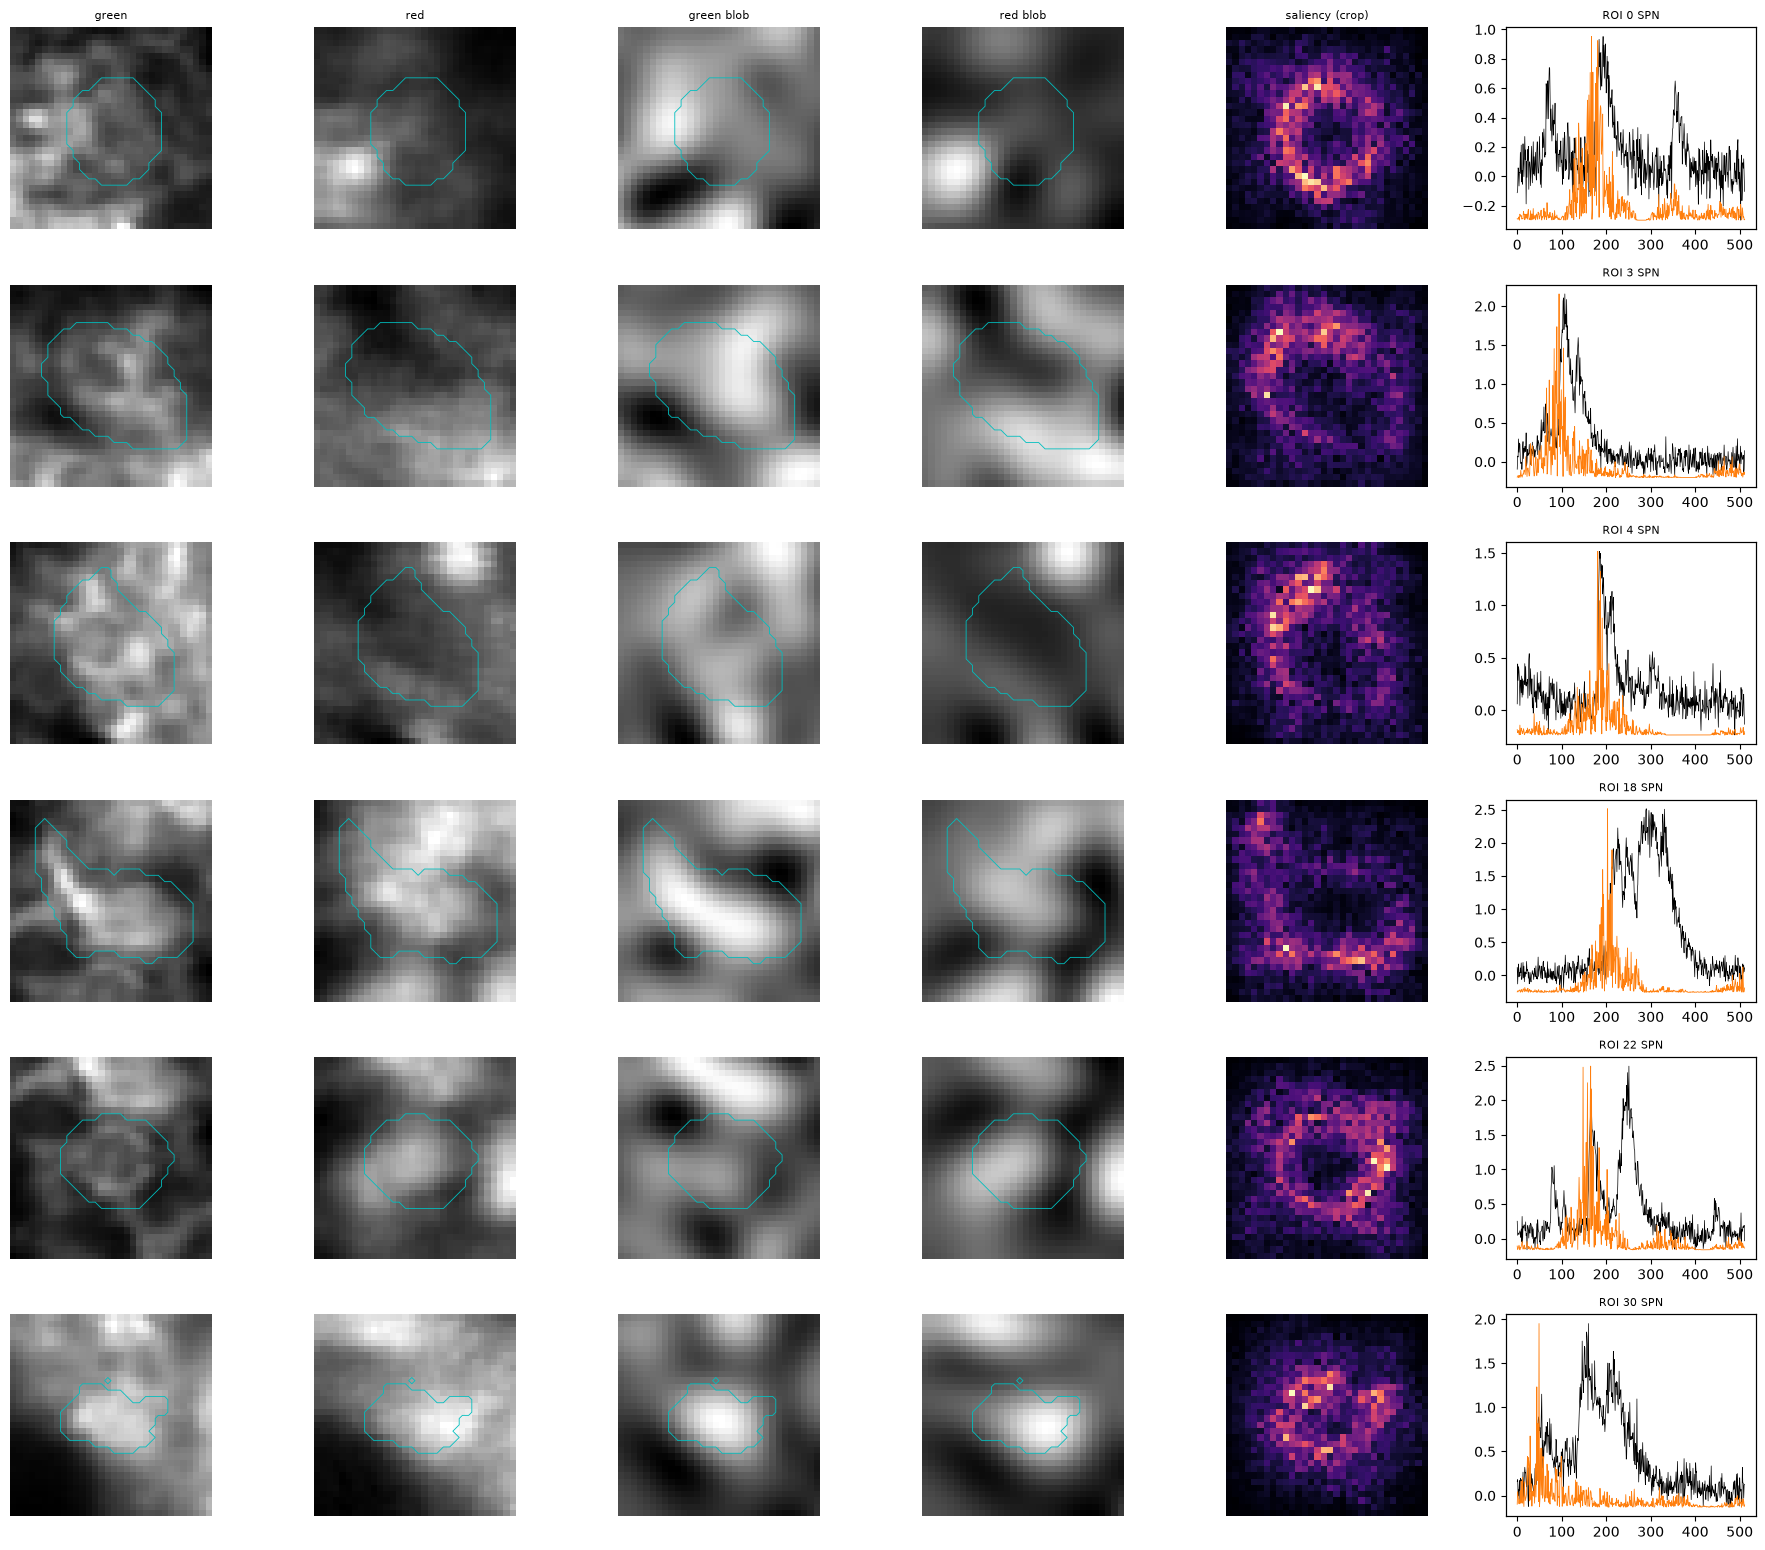

In [32]:
lab = mt.LABELS[1](rows); k = np.flatnonzero(lab >= 0)
net = mt.train_net(inputs["img"][k], inputs["trace"][k], lab[k], epochs=25)
idx = list(k[:6]); mt.show_saliency(net, inputs, idx, [f"ROI {rows.roi_idx[i]} {rows.stage1[i]}" for i in idx])

C:\Users\sammxie\AppData\Local\Temp\ipykernel_1948\3529172133.py:15: Pandas4Warning: Starting with pandas version 4.0 all arguments of min will be keyword-only.
  q = p.sub(p.min(1), axis=0).div(p.max(1) - p.min(1) + 1e-6, axis=0)                # the SHAPE: each ROI scaled 0..1
C:\Users\sammxie\AppData\Local\Temp\ipykernel_1948\3529172133.py:15: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  q = p.sub(p.min(1), axis=0).div(p.max(1) - p.min(1) + 1e-6, axis=0)                # the SHAPE: each ROI scaled 0..1
C:\Users\sammxie\AppData\Local\Temp\ipykernel_1948\3529172133.py:15: Pandas4Warning: Starting with pandas version 4.0 all arguments of min will be keyword-only.
  q = p.sub(p.min(1), axis=0).div(p.max(1) - p.min(1) + 1e-6, axis=0)                # the SHAPE: each ROI scaled 0..1
C:\Users\sammxie\AppData\Local\Temp\ipykernel_1948\3529172133.py:15: Pandas4Warning: Starting with pandas version 4.0 all arguments of min will be keyword-only.

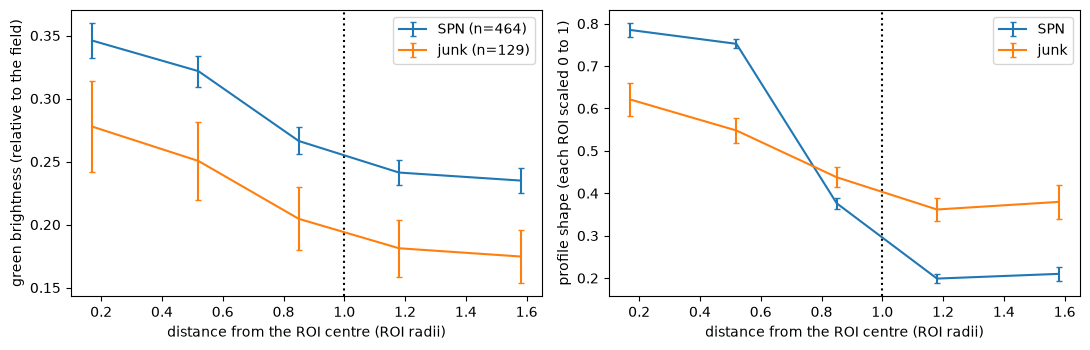

,AUC for SPN (below 0.5: higher in junk)
ringblob_slope,0.35
ring_slope,0.36
ringblob_centroid_offset,0.36
ring_centroid_offset,0.38
nucleus_shadow,0.41
ring_rim_anisotropy,0.43
green_blob,0.53
ring_edge_contrast,0.58
ring_inside_vs_halo,0.58
ringblob_rim_anisotropy,0.60


AUC (pooled)  AUC mean over held-out groups  \
logreg current                          0.953                          0.933   
       + green ring                     0.934                          0.924   
       + green ring + blob ring         0.919                          0.904   
hgb    current                          0.947                          0.929   
       + green ring                     0.944                          0.930   
       + green ring + blob ring         0.944                          0.935   

                                 balanced acc @0.5  \
logreg current                               0.903   
       + green ring                          0.895   
       + green ring + blob ring              0.879   
hgb    current                               0.892   
       + green ring                          0.882   
       + green ring + blob ring              0.881   

                                 confident calls (share of ROIs)  \
logreg current                                             0.806   
       + green ring                                        0.815   
       + green ring + blob ring                            0.815   
hgb    current                                             0.901   
       + green ring                                        0.901   
       + green ring + blob ring                            0.902   

                                 accuracy of confident calls  \
logreg current                                         0.958   
       + green ring                                    0.948   
       + green ring + blob ring                        0.940   
hgb    current                                         0.964   
       + green ring                                    0.964   
       + green ring + blob ring                        0.963   

                                 confident mistakes  
logreg current                                 20.0  
       + green ring                            25.0  
       + green ring + blob ring                29.0  
hgb    current                                 19.0  
       + green ring                            19.0  
       + green ring + blob ring                20.0

,fall in held-out AUC when shuffled,SD over folds
green ring,-0.0010,0.0111
baseline,0.0053,0.0089
size,0.0095,0.0321
nucleus / brightness,0.0141,0.0261
green blob,0.0440,0.0557
shape,0.0443,0.0396
event rate / amplitude,0.1346,0.1031
trace shape / noise,0.2544,0.1149


In [35]:
import importlib
from celltype import model_test as mt
mt = importlib.reload(mt)                      # pick up green_ring_features / radial_profile
from sklearn.metrics import roc_auc_score

# needs from before: rows, inputs (mt.build_inputs), COLS1, cfg; from the training notebook: DATA, run_cv, summary, GROUPS, MODEL1
lab = mt.LABELS[1](rows); k = np.flatnonzero(lab >= 0)                 # stage 1 only: SPN (1) vs interneuron / junk (0); no red channel anywhere here

# ===== 1. what does the GREEN brightness look like around SPNs and junk? (mean +- SE; distance in ROI radii) =====
prof = {name: mt.radial_profile(inputs, k[lab[k] == v], channel=0) for name, v in (("SPN", 1), ("junk", 0))}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for name, p in prof.items():
    x = p.columns.astype(float)
    ax[0].errorbar(x, p.mean(), p.std() / np.sqrt(p.count()), label=f"{name} (n={len(p)})", capsize=2)
    q = p.sub(p.min(1), axis=0).div(p.max(1) - p.min(1) + 1e-6, axis=0)                # the SHAPE: each ROI scaled 0..1
    ax[1].errorbar(x, q.mean(), q.std() / np.sqrt(q.count()), label=name, capsize=2)
for a, t in zip(ax, ("green brightness (relative to the field)", "profile shape (each ROI scaled 0 to 1)")):
    a.axvline(1, color="k", ls=":"); a.set_xlabel("distance from the ROI centre (ROI radii)"); a.set_ylabel(t); a.legend()
plt.tight_layout(); plt.show()

# ===== 2. the green ring features: AUC for SPN vs junk, next to what we already have =====
g = mt.green_ring_features(inputs, channel=0, prefix="ring")           # green image
gb = mt.green_ring_features(inputs, channel=2, prefix="ringblob")      # green blob map
newc, newb = list(g.columns), list(gb.columns)
rows3 = pd.concat([rows.reset_index(drop=True), g, gb], axis=1)
t = rows3.iloc[k].assign(y=lab[k])
cand = newc + newb + ["nucleus_shadow", "green_blob", "solidity", "circularity", "skew"]
aucs = pd.Series({c: roc_auc_score(t.y, t[c].fillna(t[c].median())) for c in cand}).sort_values()
display(aucs.round(2).to_frame("AUC for SPN (below 0.5: higher in junk)"))

# ===== 3. do they help the SPN / not-SPN model? cross-validation, logistic regression and boosted trees =====
GROUPS[1]["green ring"] = newc; GROUPS[1]["green-blob ring"] = newb
DATA_backup, MODEL_backup = DATA, MODEL1
DATA = rows3                                                           # run_cv reads the global DATA
out = {}
try:
    for model in ("logreg", "hgb"):
        MODEL1 = model
        for name, cols in (("current", COLS1), ("+ green ring", COLS1 + newc), ("+ green ring + blob ring", COLS1 + newc + newb)):
            out[(model, name)] = summary(run_cv(1, cols))
    MODEL1 = "logreg"
    res = run_cv(1, COLS1 + newc, importance=True)                     # permutation importance of the new group
finally:
    DATA, MODEL1 = DATA_backup, MODEL_backup
cols_show = ["AUC (pooled)", "AUC mean over held-out groups", "balanced acc @0.5", "confident calls (share of ROIs)",
             "accuracy of confident calls", "confident mistakes"]
display(pd.DataFrame(out).T[cols_show].round(3))
display(pd.DataFrame({"fall in held-out AUC when shuffled": res["imp_g"].mean(), "SD over folds": res["imp_g"].std()}).sort_values("fall in held-out AUC when shuffled").round(4))

  computed ['green_z', 'green_max_z', 'green_max_rel', 'green_max_blob', 'max_mean_logratio', 'neuropil_corr', 'common_mode_corr', 'rise_decay_asym'] for 9 session(s): the table was made by an older features.py
p_animals\mouse1\260925\932_GUI_rec000     12 ROIs,   12 with >= 3 events,     2 s so far
_animals\mouse1\260929\932_3dir_rec000     58 ROIs,   58 with >= 3 events,    12 s so far
_animals\mouse1\260929\932_3dir_rec001      1 ROIs,    1 with >= 3 events,    14 s so far
als\mouse1\261012\932_1dir_left_rec002     27 ROIs,   27 with >= 3 events,    26 s so far
_animals\mouse1\261013\932_3dir_rec000     25 ROIs,   25 with >= 3 events,    37 s so far
_animals\mouse1\261013\932_3dir_rec001     20 ROIs,   20 with >= 3 events,    53 s so far
als\mouse1\261014\932_1dir_left_rec001    263 ROIs,  263 with >= 3 events,    71 s so far
als\mouse1\261014\932_1dir_left_rec002    103 ROIs,  103 with >= 3 events,    86 s so far
_animals\mouse1\261020\932_3dir_rec000     84 ROIs,   84 with >= 3 ev

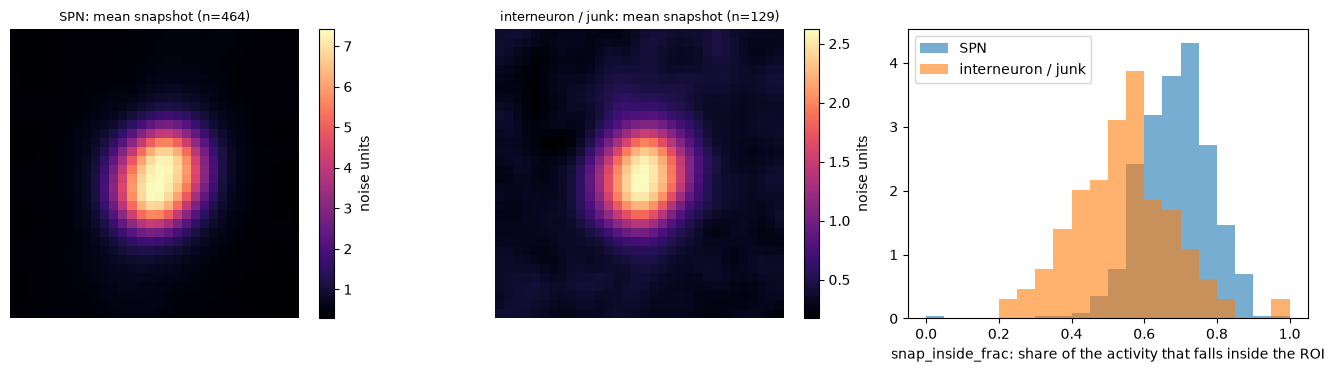

share of ROIs with no snapshot (fewer than 3 events), by class: {'junk': 0.0, 'SPN': 0.0}


,AUC for SPN (below 0.5: higher in junk; NaN filled with the median)
snap_spread,0.22
snap_offset,0.26
lam_offset,0.33
lam_peak,0.43
green_z,0.51
max_mean_logratio,0.52
lam_cv,0.55
green_max_z,0.62
lam_corr_mean,0.63
green_max_rel,0.64


AUC (pooled)  \
logreg A: base (no max image)                                     0.960   
       B: + whole-frame max features (v5)                         0.963   
       C: + Suite2p weights                                       0.953   
       D: + event snapshot (instead of the whole-frame...         0.963   
       E: snapshot + weights                                      0.960   
       F: whole-frame max + snapshot                              0.964   
hgb    A: base (no max image)                                     0.958   
       B: + whole-frame max features (v5)                         0.957   
       C: + Suite2p weights                                       0.961   
       D: + event snapshot (instead of the whole-frame...         0.976   
       E: snapshot + weights                                      0.975   
       F: whole-frame max + snapshot                              0.975   

                                                           AUC mean over held-out groups  \
logreg A: base (no max image)                                                      0.934   
       B: + whole-frame max features (v5)                                          0.919   
       C: + Suite2p weights                                                        0.923   
       D: + event snapshot (instead of the whole-frame...                          0.943   
       E: snapshot + weights                                                       0.930   
       F: whole-frame max + snapshot                                               0.930   
hgb    A: base (no max image)                                                      0.925   
       B: + whole-frame max features (v5)                                          0.930   
       C: + Suite2p weights                                                        0.924   
       D: + event snapshot (instead of the whole-frame...                          0.982   
       E: snapshot + weights                                                       0.977   
       F: whole-frame max + snapshot                                               0.979   

                                                           balanced acc @0.5  \
logreg A: base (no max image)                                          0.921   
       B: + whole-frame max features (v5)                              0.908   
       C: + Suite2p weights                                            0.915   
       D: + event snapshot (instead of the whole-frame...              0.904   
       E: snapshot + weights                                           0.911   
       F: whole-frame max + snapshot                                   0.918   
hgb    A: base (no max image)                                          0.898   
       B: + whole-frame max features (v5)                              0.879   
       C: + Suite2p weights                                            0.896   
       D: + event snapshot (instead of the whole-frame...              0.914   
       E: snapshot + weights                                           0.910   
       F: whole-frame max + snapshot                                   0.915   

                                                           confident calls (share of ROIs)  \
logreg A: base (no max image)                                                        0.798   
       B: + whole-frame max features (v5)                                            0.830   
       C: + Suite2p weights                                                          0.804   
       D: + event snapshot (instead of the whole-frame...                            0.860   
       E: snapshot + weights                                                         0.848   
       F: whole-frame max + snapshot                                                 0.872   
hgb    A: base (no max image)                                                        0.889   
       B: + whole-frame max features (v5)                                            0.890   

,fall in held-out AUC when shuffled,SD over folds
baseline,0.0031,0.0117
nucleus / brightness,0.0045,0.0111
whole-frame max,0.0051,0.0221
shape,0.0062,0.0246
green blob,0.0170,0.0258
size,0.0203,0.0394
trace shape / noise,0.0488,0.0154
event rate / amplitude,0.0776,0.1424
event snapshot,0.1177,0.1006


In [40]:
import importlib, time
from celltype import io_utils, features, models as _models, feature_tests
for m in (io_utils, features, _models, feature_tests):     # re-read the current code (in this order); a no-op if nothing changed
    importlib.reload(m)
from celltype import feature_tests as mt, features as ft
from sklearn.metrics import roc_auc_score

# needs from before: rows (the labeled ROIs of the training table: session_dir, roi_idx, stage1, features ...), cfg;
# from the training notebook: DATA, run_cv, summary, GROUPS, MODEL1, STAGE
SESSIONS = None      # None = every session of `rows`. Try rows.session_dir.unique()[:2].tolist() first to see the time per session
sess_list = rows.session_dir.unique().tolist() if SESSIONS is None else list(SESSIONS)
sub = pd.concat([rows[rows.session_dir == s] for s in sess_list]).reset_index(drop=True)
sub = mt.ensure_columns(sub, cfg, ft.MORPH + ft.ACTIVITY)       # a table made by an older features.py lacks the newer columns: computed here

# ===== 1. compute the two new feature groups for the labeled ROIs of every session =====
lam, snap, imgs, t0 = [], [], [], time.time()
for s in sess_list:
    ids = sub.loc[sub.session_dir == s, "roi_idx"].astype(int).tolist()
    lam.append(mt.lam_features(s, cfg, ids).assign(session_dir=s))                       # Suite2p weights, no movie
    f, im = mt.snapshot_features(s, cfg, ids, return_images=True)                         # event snapshot, reads the movie
    snap.append(f.assign(session_dir=s)); imgs.append(im)
    print(f"{str(s)[-38:]:40s} {len(ids):4d} ROIs, {int((f.snap_n_events >= 3).sum()):4d} with >= 3 events, {time.time() - t0:5.0f} s so far")
sub3 = sub.merge(pd.concat(lam), on=["session_dir", "roi_idx"], how="left").merge(pd.concat(snap), on=["session_dir", "roi_idx"], how="left")
allimg = np.concatenate(imgs)                                                             # same row order as sub3
lab = mt.LABELS[1](sub3)                                                                  # stage 1: SPN 1, interneuron / junk 0, else -1

# ===== 2. what do the snapshots look like? mean snapshot per class, and one feature =====
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
mid = allimg.shape[-1] // 2
for a, (name, m) in zip(ax[:2], (("SPN", lab == 1), ("interneuron / junk", lab == 0))):
    has = m & np.isfinite(allimg[:, mid, mid])
    im = a.imshow(np.nanmean(allimg[has], 0), cmap="magma"); a.set_title(f"{name}: mean snapshot (n={int(has.sum())})", fontsize=9); a.axis("off"); plt.colorbar(im, ax=a, fraction=.046, label="noise units")
for name, m in (("SPN", lab == 1), ("interneuron / junk", lab == 0)):
    ax[2].hist(sub3.loc[m, "snap_inside_frac"].dropna(), np.linspace(0, 1, 21), alpha=.6, label=name, density=True)
ax[2].set_xlabel("snap_inside_frac: share of the activity that falls inside the ROI"); ax[2].legend(); plt.tight_layout(); plt.show()
t = sub3[lab >= 0].assign(y=lab[lab >= 0])
print("share of ROIs with no snapshot (fewer than 3 events), by class:", t.groupby("y").snap_peak_z.apply(lambda s: round(float(s.isna().mean()), 2)).rename({0: "junk", 1: "SPN"}).to_dict())

# ===== 3. AUC of every new feature next to the ones we have =====
cand = mt.SNAP_COLS + mt.LAM_COLS + ft.GREEN_MAX + ["skew", "solidity"]
aucs = pd.Series({c: roc_auc_score(t.y, t[c].fillna(t[c].median())) for c in cand if t[c].notna().sum() > 10}).sort_values()
display(aucs.round(2).to_frame("AUC for SPN (below 0.5: higher in junk; NaN filled with the median)"))

# ===== 4. cross-validation: does it help the SPN / not-SPN model, and does the snapshot replace the whole-frame max? =====
BASE = [c for c in ft.MORPH + ft.ACTIVITY if c not in ft.GREEN_MAX]                       # no max-image features at all
sets = {"A: base (no max image)": BASE,
        "B: + whole-frame max features (v5)": BASE + ft.GREEN_MAX,
        "C: + Suite2p weights": BASE + mt.LAM_COLS,
        "D: + event snapshot (instead of the whole-frame max)": BASE + mt.SNAP_COLS,
        "E: snapshot + weights": BASE + mt.SNAP_COLS + mt.LAM_COLS,
        "F: whole-frame max + snapshot": BASE + ft.GREEN_MAX + mt.SNAP_COLS}
GROUPS[1]["event snapshot"] = mt.SNAP_COLS; GROUPS[1]["Suite2p weights"] = mt.LAM_COLS; GROUPS[1]["whole-frame max"] = ft.GREEN_MAX
DATA_backup, MODEL_backup = DATA, MODEL1
DATA = sub3                                                                               # run_cv reads the global DATA
out = {}
try:
    for model in ("logreg", "hgb"):
        MODEL1 = model
        for name, cols in sets.items():
            out[(model, name)] = summary(run_cv(1, cols))
    MODEL1 = "logreg"
    res = run_cv(1, sets["F: whole-frame max + snapshot"], importance=True)               # which group matters when all are in
finally:
    DATA, MODEL1 = DATA_backup, MODEL_backup
show = ["AUC (pooled)", "AUC mean over held-out groups", "balanced acc @0.5", "confident calls (share of ROIs)", "accuracy of confident calls", "confident mistakes"]
display(pd.DataFrame(out).T[show].round(3))
display(pd.DataFrame({"fall in held-out AUC when shuffled": res["imp_g"].mean(), "SD over folds": res["imp_g"].std()}).sort_values("fall in held-out AUC when shuffled").round(4))

  computed ['green_z', 'green_max_z', 'green_max_rel', 'green_max_blob', 'max_mean_logratio', 'neuropil_corr', 'common_mode_corr', 'rise_decay_asym'] for 9 session(s): the table was made by an older features.py
p_animals\mouse1\260925\932_GUI_rec000     12 ROIs      2 s so far
_animals\mouse1\260929\932_3dir_rec000     58 ROIs     12 s so far
_animals\mouse1\260929\932_3dir_rec001      1 ROIs     15 s so far
als\mouse1\261012\932_1dir_left_rec002     27 ROIs     25 s so far
_animals\mouse1\261013\932_3dir_rec000     25 ROIs     36 s so far
_animals\mouse1\261013\932_3dir_rec001     20 ROIs     52 s so far
als\mouse1\261014\932_1dir_left_rec001    263 ROIs     73 s so far
als\mouse1\261014\932_1dir_left_rec002    103 ROIs     90 s so far
_animals\mouse1\261020\932_3dir_rec000     84 ROIs    122 s so far

===== stage 1 (SPN vs not), logreg, leave-one-session-out =====


,AUC (pooled),AUC mean over held-out groups,balanced acc @0.5,confident calls (share of ROIs),accuracy of confident calls,confident mistakes
A: base,0.960,0.934,0.921,0.798,0.962,18.0
B: + whole-frame max (what features.py has now),0.963,0.919,0.908,0.830,0.974,13.0
D: + event snapshot (new),0.963,0.943,0.904,0.860,0.965,18.0


held-out AUC per session, snapshot minus base: mean +0.009 +- 0.011 (SE) over 7 sessions; better in 4


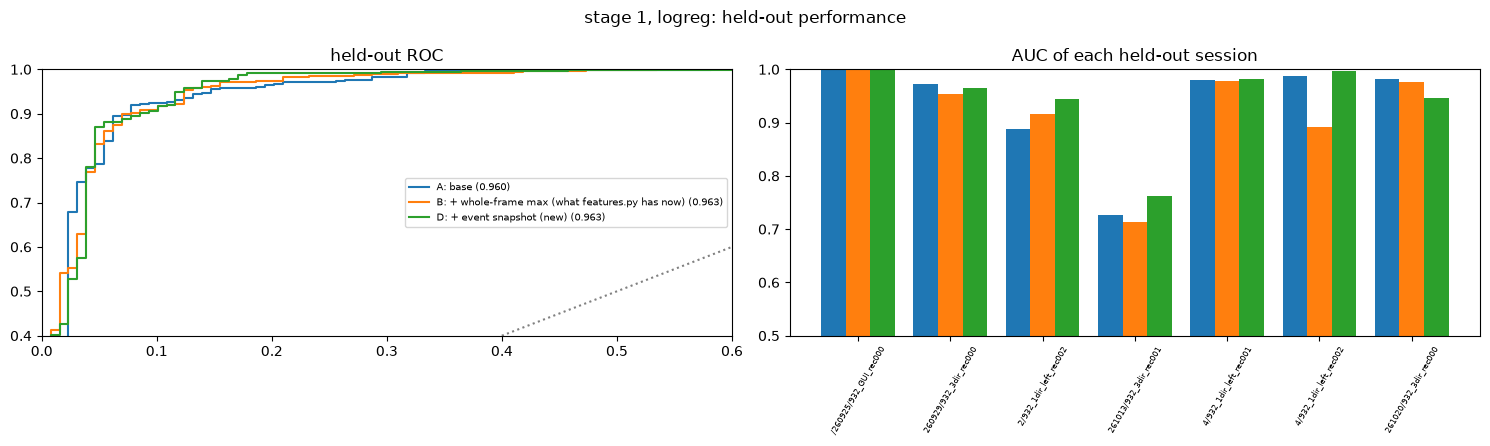


===== stage 1 (SPN vs not), hgb, leave-one-session-out =====


,AUC (pooled),AUC mean over held-out groups,balanced acc @0.5,confident calls (share of ROIs),accuracy of confident calls,confident mistakes
A: base,0.958,0.925,0.898,0.889,0.964,19.0
B: + whole-frame max (what features.py has now),0.957,0.930,0.879,0.890,0.962,20.0
D: + event snapshot (new),0.976,0.982,0.914,0.926,0.965,19.0


held-out AUC per session, snapshot minus base: mean +0.057 +- 0.043 (SE) over 7 sessions; better in 3


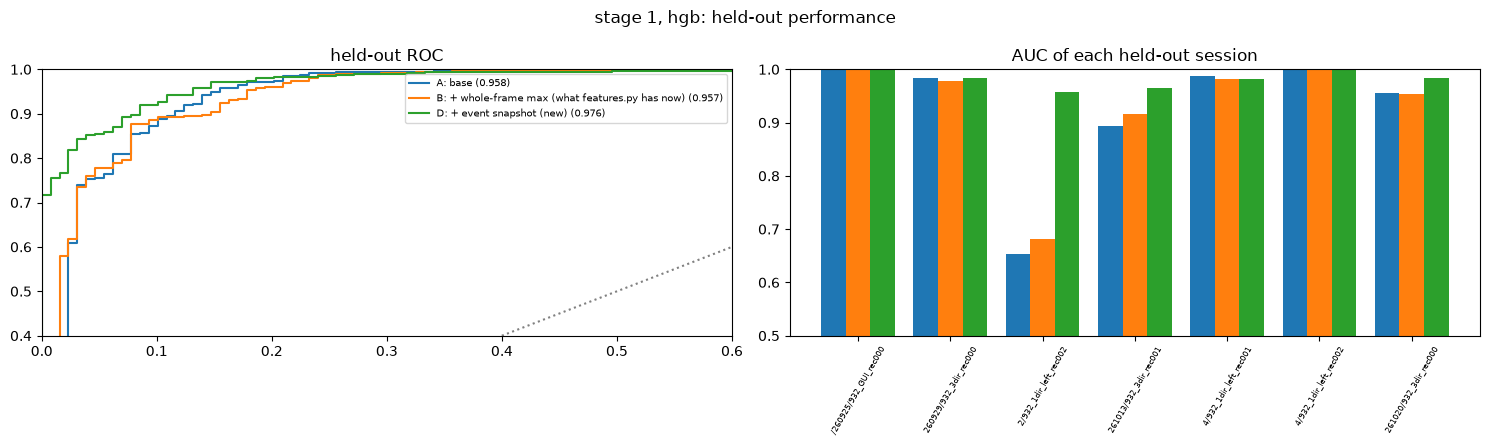


===== stage 2 (red+ vs red-), logreg =====


,AUC (pooled),AUC mean over held-out groups,balanced acc @0.5,confident calls (share of ROIs),accuracy of confident calls,confident mistakes
A: current red features,0.945,0.934,0.886,0.697,0.945,15.0
"G: + red-green ratio, correlation, overlap (new)",0.939,0.929,0.885,0.718,0.940,17.0


held-out AUC per session, with minus without the red-green features: mean -0.005 +- 0.006 (SE) over 8 sessions; better in 1


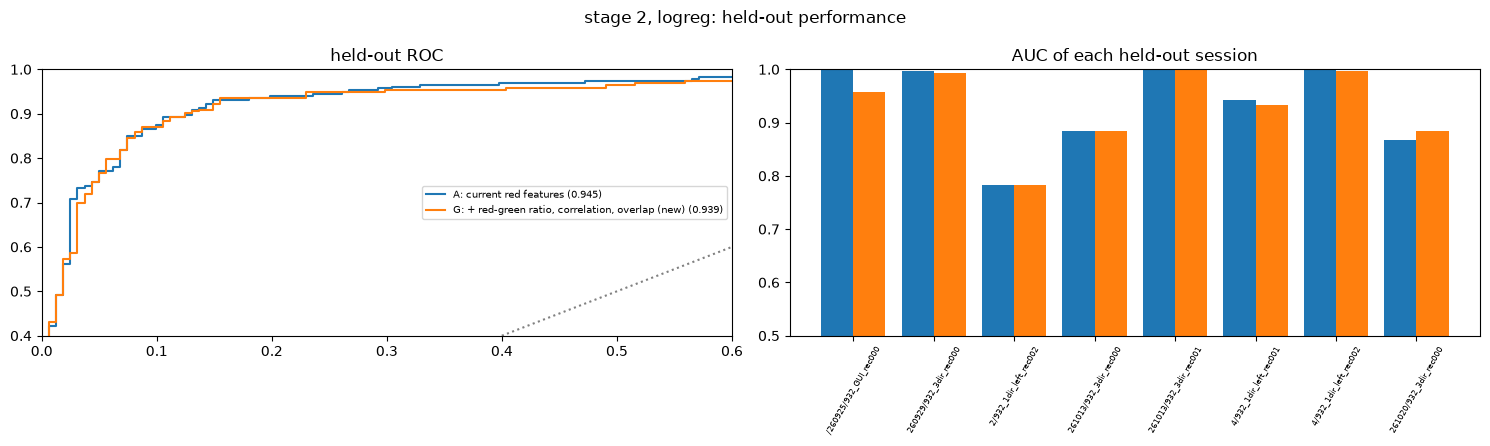


===== stage 2 (red+ vs red-), hgb =====


,AUC (pooled),AUC mean over held-out groups,balanced acc @0.5,confident calls (share of ROIs),accuracy of confident calls,confident mistakes
A: current red features,0.908,0.920,0.861,0.858,0.887,38.0
"G: + red-green ratio, correlation, overlap (new)",0.915,0.915,0.861,0.840,0.894,35.0


held-out AUC per session, with minus without the red-green features: mean -0.006 +- 0.005 (SE) over 8 sessions; better in 2


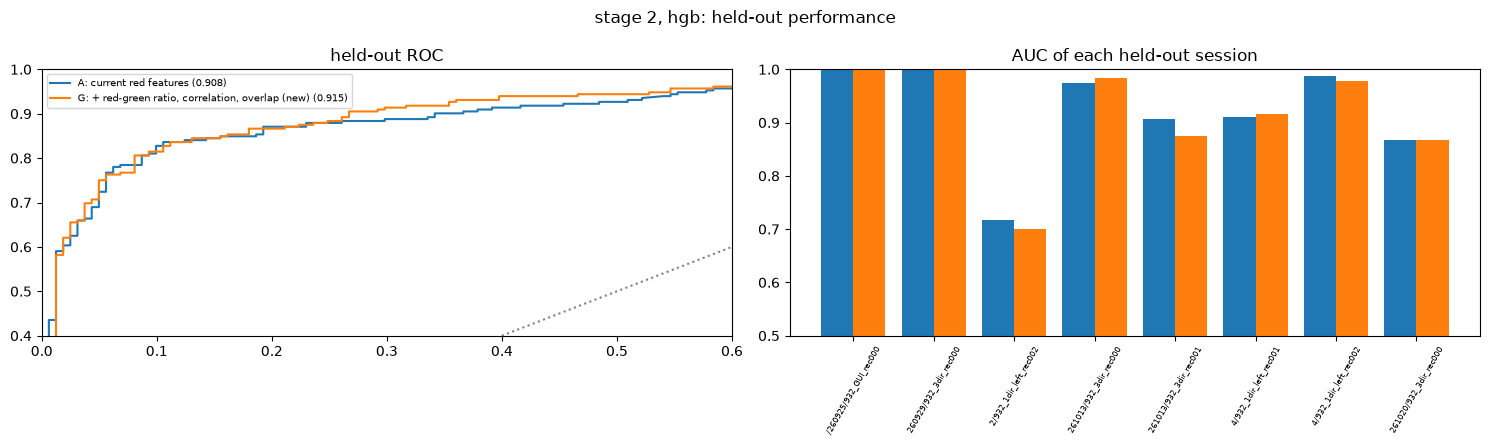

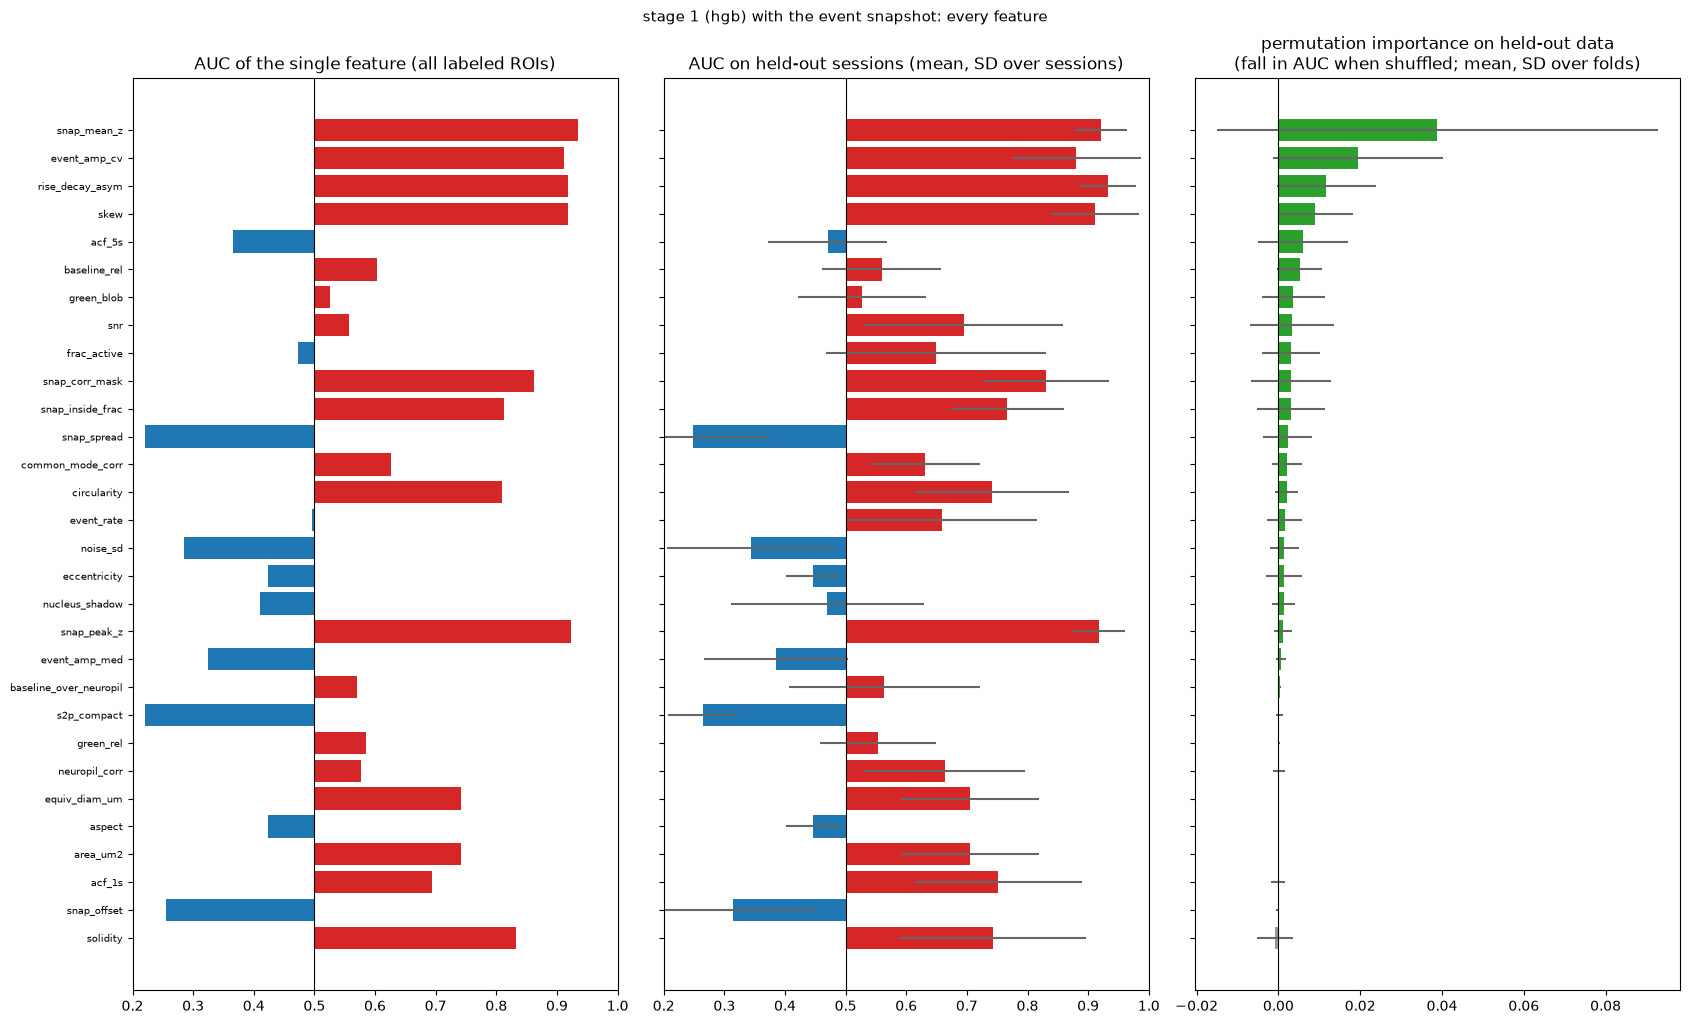

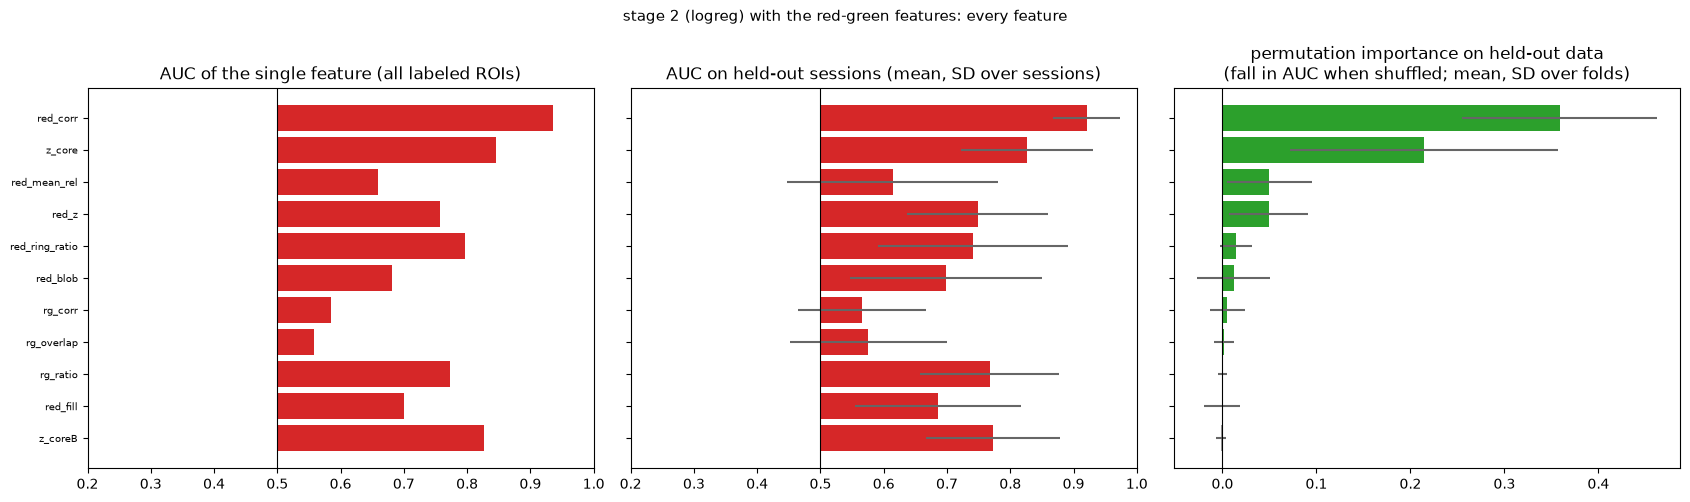

,AUC,AUC held-out sessions,AUC SD,importance,importance SD
feature,,,,,
snap_mean_z,0.934,0.921,0.043,0.039,0.054
event_amp_cv,0.911,0.880,0.106,0.019,0.021
rise_decay_asym,0.917,0.932,0.047,0.012,0.012
skew,0.918,0.911,0.073,0.009,0.009
acf_5s,0.366,0.470,0.098,0.006,0.011
baseline_rel,0.603,0.560,0.098,0.005,0.005
green_blob,0.525,0.527,0.106,0.004,0.008
snr,0.557,0.695,0.165,0.003,0.010
frac_active,0.472,0.650,0.181,0.003,0.007


,AUC,AUC held-out sessions,AUC SD,importance,importance SD
feature,,,,,
red_corr,0.935,0.921,0.053,0.359,0.104
z_core,0.846,0.827,0.104,0.215,0.143
red_mean_rel,0.659,0.614,0.167,0.050,0.045
red_z,0.758,0.748,0.112,0.049,0.042
red_ring_ratio,0.797,0.741,0.150,0.015,0.017
red_blob,0.682,0.699,0.152,0.012,0.039
rg_corr,0.586,0.566,0.101,0.005,0.018
rg_overlap,0.558,0.576,0.124,0.002,0.010
rg_ratio,0.773,0.767,0.110,0.000,0.005


In [41]:
import importlib, time
from celltype import io_utils, features, models as _models, feature_tests
for m in (io_utils, features, _models, feature_tests):     # re-read the current code (in this order); a no-op if nothing changed
    importlib.reload(m)
from celltype import feature_tests as mt, features as ft
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# needs from before: rows (the labeled ROIs of the training table), cfg; from the training notebook: run_cv, summary, STAGE, GROUPS,
# MODEL1, N_REPEATS, DATA, make_model (rerun its cells first)
SESSIONS = None                                  # None = every session of `rows`; e.g. rows.session_dir.unique()[:3].tolist() for a first look
STAGE1_MODEL, STAGE2_MODEL = "hgb", "logreg"     # the models of the final feature reports (part 3)
N_REPEATS = 10                                   # permutation repeats of the importance (the training notebook's variable)

# ===== 0. the labeled ROIs with the new features (the snapshots and red-green features are slow: kept in FEAT_CACHE for reruns) =====
FEAT_CACHE = globals().get("FEAT_CACHE", {})
sess_list = rows.session_dir.unique().tolist() if SESSIONS is None else list(SESSIONS)
sub = pd.concat([rows[rows.session_dir == s] for s in sess_list]).reset_index(drop=True)
sub = mt.ensure_columns(sub, cfg, ft.MORPH + ft.ACTIVITY)                       # a table from an older features.py lacks the newer columns: computed here
lacking = [c for c in ft.RED if c not in sub.columns]
if lacking:
    raise RuntimeError(f"the table lacks the red features {lacking}: rerun cell 1 of the training notebook (it recomputes the table)")
snap, rg, t0 = [], [], time.time()
for s in sess_list:
    ids = sub.loc[sub.session_dir == s, "roi_idx"].astype(int).tolist()
    if (s, tuple(ids)) not in FEAT_CACHE:
        FEAT_CACHE[(s, tuple(ids))] = (mt.snapshot_features(s, cfg, ids).assign(session_dir=s), mt.rg_features(s, cfg, ids).assign(session_dir=s))
    a, b = FEAT_CACHE[(s, tuple(ids))]; snap.append(a); rg.append(b)
    print(f"{str(s)[-38:]:40s} {len(ids):4d} ROIs  {time.time() - t0:5.0f} s so far")
sub3 = sub.merge(pd.concat(snap), on=["session_dir", "roi_idx"], how="left").merge(pd.concat(rg), on=["session_dir", "roi_idx"], how="left")

# stage 2 can be boosted trees too in this notebook (the training notebook's make_model has logistic regression only there)
MODEL2 = "logreg"
make_model_backup = make_model
def make_model(which):
    kind = MODEL1 if which == 1 else MODEL2
    clf = (HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, class_weight="balanced") if kind == "hgb"
           else LogisticRegression(class_weight="balanced", max_iter=2000))
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), clf)

BASE1 = [c for c in ft.MORPH + ft.ACTIVITY if c not in ft.GREEN_MAX]                     # stage 1 without any max-image feature
SETS1 = {"A: base": BASE1,
         "B: + whole-frame max (what features.py has now)": BASE1 + ft.GREEN_MAX,
         "D: + event snapshot (new)": BASE1 + mt.SNAP_COLS}
SETS2 = {"A: current red features": list(ft.RED),
         "G: + red-green ratio, correlation, overlap (new)": list(ft.RED) + mt.RG_COLS}
show = ["AUC (pooled)", "AUC mean over held-out groups", "balanced acc @0.5", "confident calls (share of ROIs)", "accuracy of confident calls", "confident mistakes"]
DATA_backup, MODEL_backup = DATA, MODEL1
DATA = sub3                                                                               # run_cv reads the global DATA
try:
    # ===== 1. STAGE 1: does the snapshot raise the held-out accuracy? (logistic regression and boosted trees) =====
    for model in ("logreg", "hgb"):
        MODEL1 = model
        r = {name: run_cv(1, cols) for name, cols in SETS1.items()}
        print(f"\n===== stage 1 (SPN vs not), {model}, leave-one-{'animal' if sub3.animal.nunique() > 1 else 'session'}-out =====")
        display(pd.DataFrame({n: summary(x) for n, x in r.items()}).T[show].round(3))
        f = pd.DataFrame({n: x["folds"].set_index("held out")["AUC"] for n, x in r.items()})
        d = (f["D: + event snapshot (new)"] - f["A: base"]).dropna()
        print(f"held-out AUC per session, snapshot minus base: mean {d.mean():+.3f} +- {d.std() / np.sqrt(len(d)):.3f} (SE) over {len(d)} sessions; better in {int((d > 0).sum())}")
        mt.plot_compare(r, f"stage 1, {model}: held-out performance")

    # ===== 2. STAGE 2: do the red-green features raise the held-out accuracy? =====
    for model in ("logreg", "hgb"):
        MODEL2 = model
        r = {name: run_cv(2, cols) for name, cols in SETS2.items()}
        print(f"\n===== stage 2 (red+ vs red-), {model} =====")
        display(pd.DataFrame({n: summary(x) for n, x in r.items()}).T[show].round(3))
        f = pd.DataFrame({n: x["folds"].set_index("held out")["AUC"] for n, x in r.items()})
        d = (f.iloc[:, 1] - f.iloc[:, 0]).dropna()
        print(f"held-out AUC per session, with minus without the red-green features: mean {d.mean():+.3f} +- {d.std() / np.sqrt(len(d)):.3f} (SE) over {len(d)} sessions; better in {int((d > 0).sum())}")
        mt.plot_compare(r, f"stage 2, {model}: held-out performance")

    # ===== 3. every feature: AUC (all ROIs and held-out sessions) and permutation importance on held-out data =====
    MODEL1, MODEL2 = STAGE1_MODEL, STAGE2_MODEL
    res1 = run_cv(1, SETS1["D: + event snapshot (new)"], importance=True)
    t1 = mt.feature_table(res1); mt.plot_feature_report(t1, f"stage 1 ({STAGE1_MODEL}) with the event snapshot: every feature")
    res2 = run_cv(2, SETS2["G: + red-green ratio, correlation, overlap (new)"], importance=True)
    t2 = mt.feature_table(res2); mt.plot_feature_report(t2, f"stage 2 ({STAGE2_MODEL}) with the red-green features: every feature")
finally:
    DATA, MODEL1 = DATA_backup, MODEL_backup
    make_model = make_model_backup
display(t1.sort_values("importance", ascending=False).round(3))
display(t2.sort_values("importance", ascending=False).round(3))

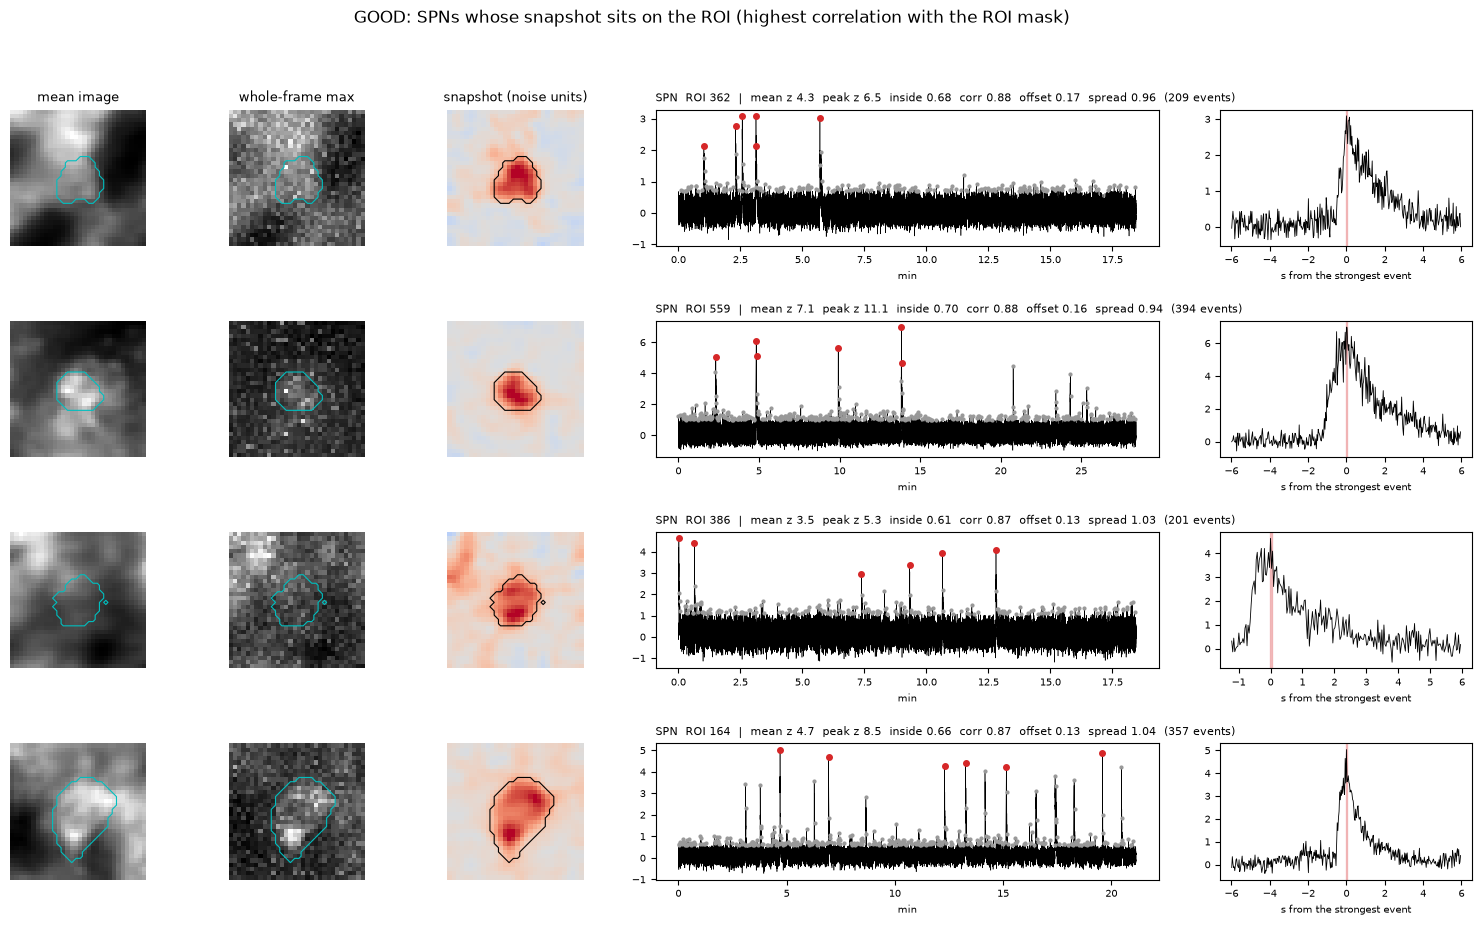

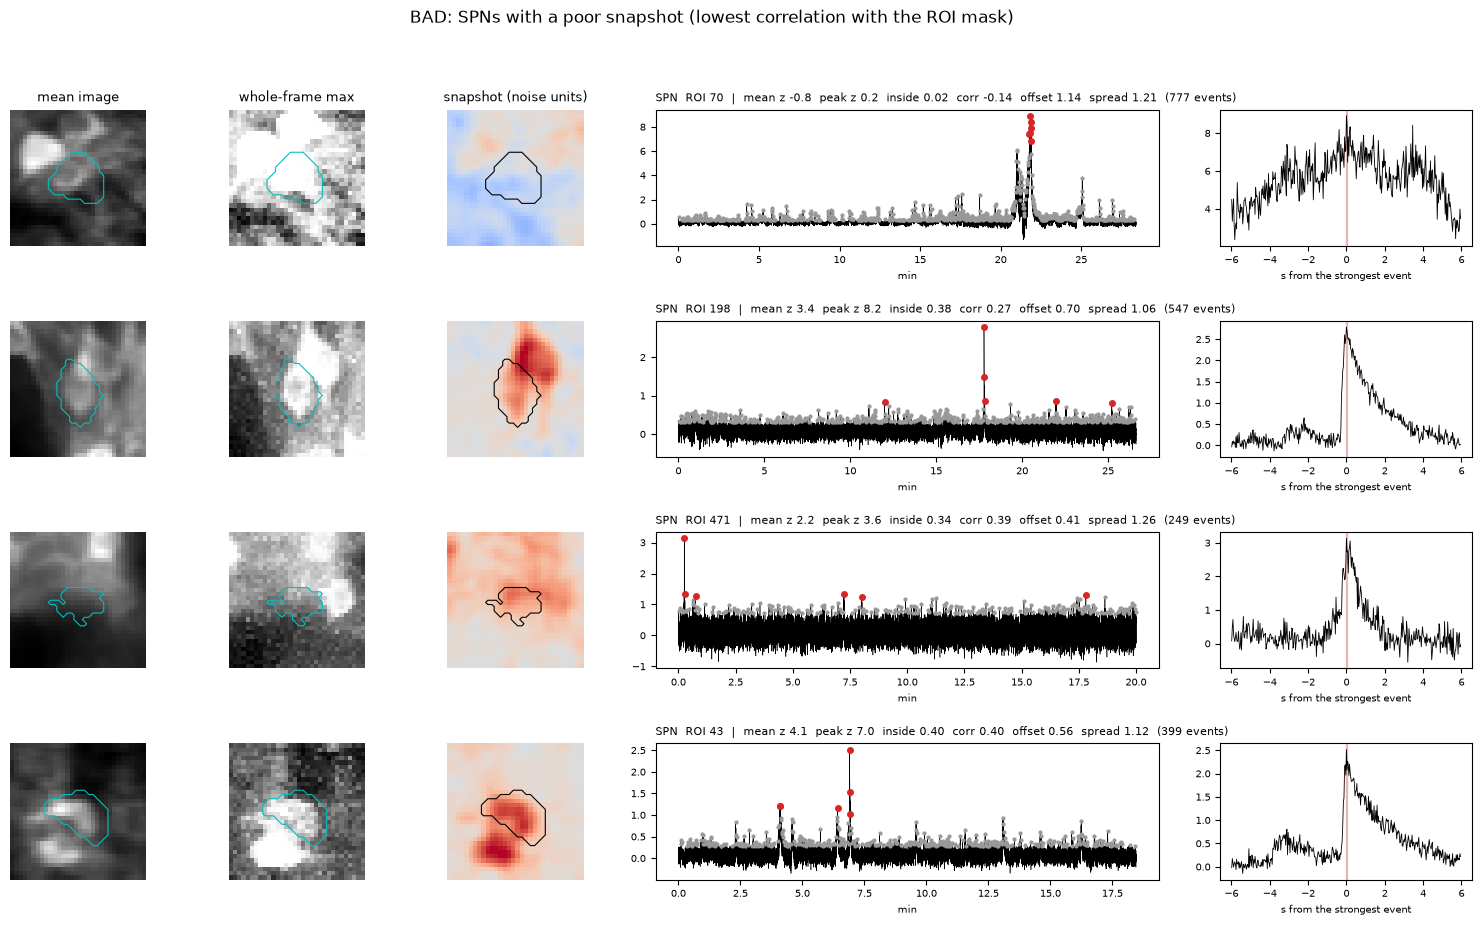

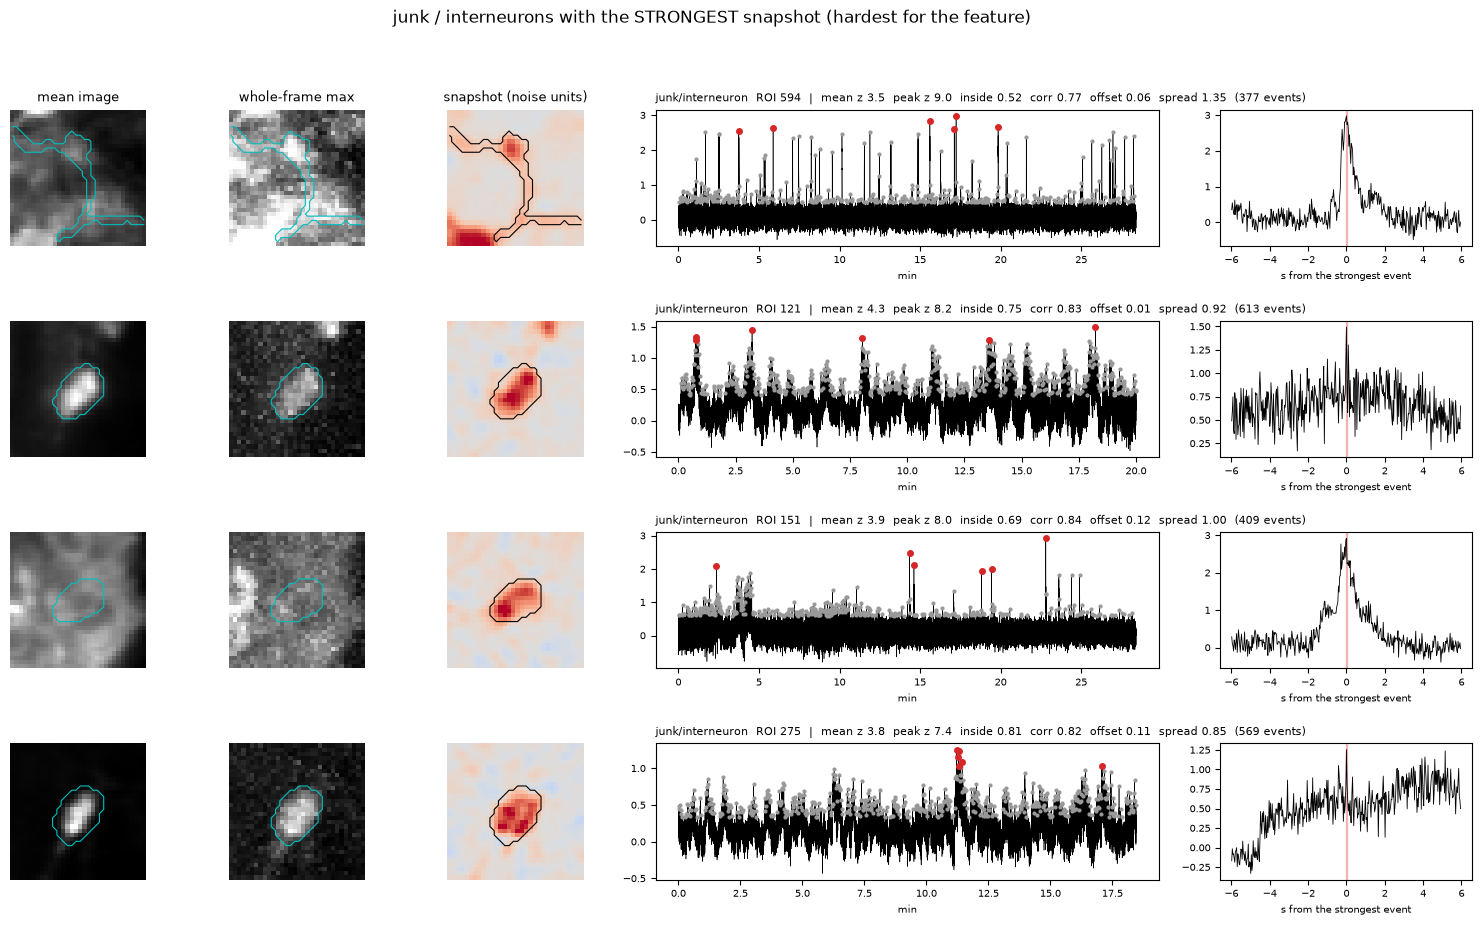

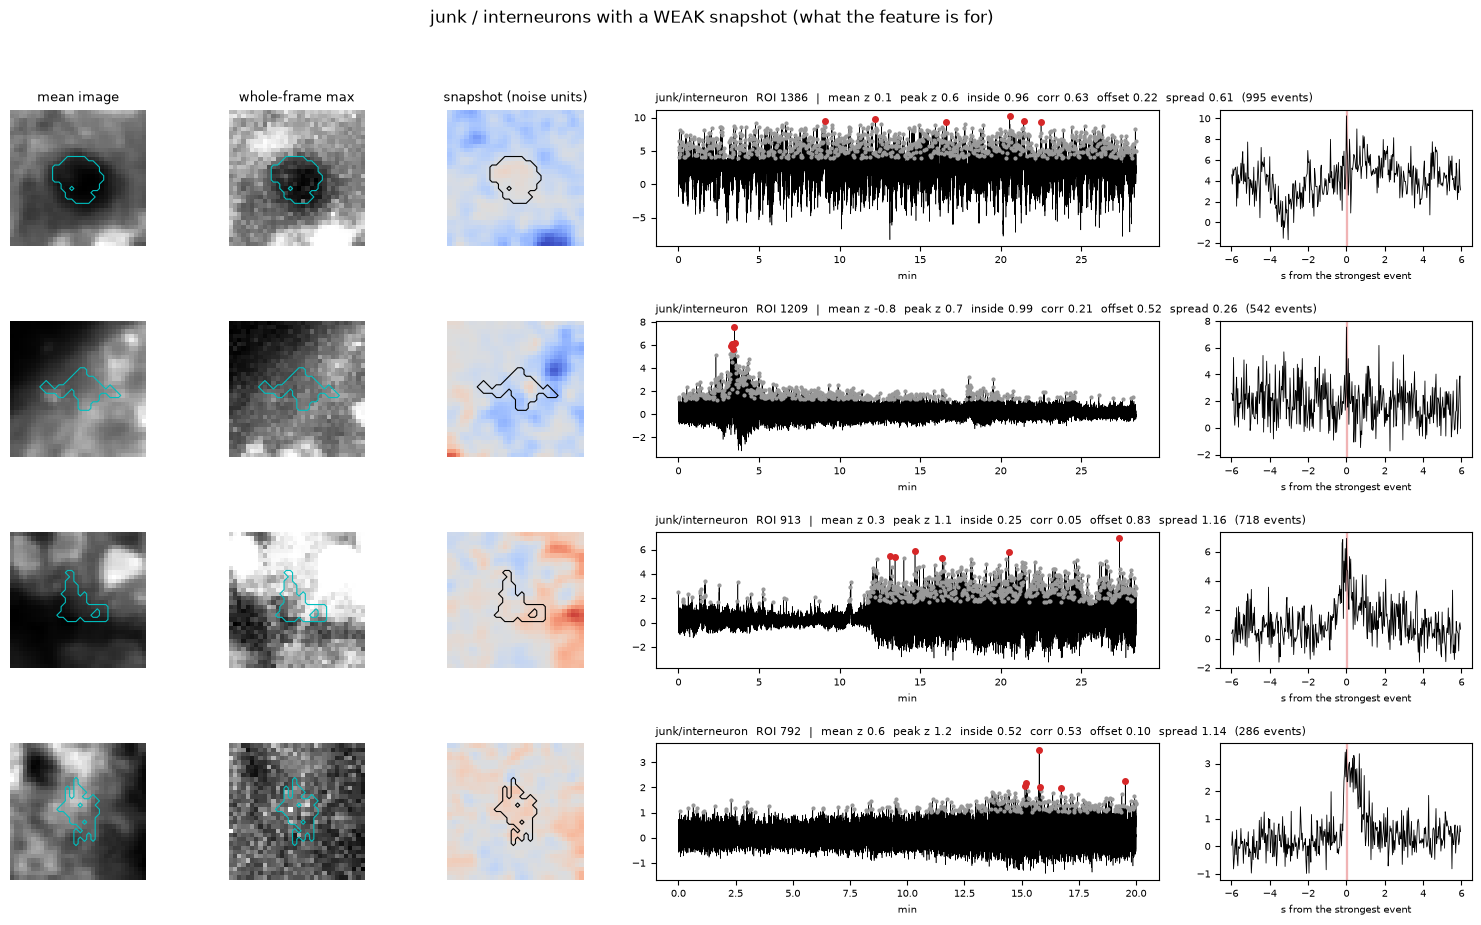

In [42]:
import importlib
from celltype import io_utils, features, feature_tests
for m in (io_utils, features, feature_tests):     # re-read the current code (in this order)
    importlib.reload(m)
from celltype import feature_tests as mt

# needs from the previous block: sub3 (the labeled ROIs with the snapshot columns snap_*, session_dir, roi_idx, stage1), cfg
N = 4                  # examples per group
RANDOM = False         # False: the extremes of each group (clearest / poorest); True: N random ones of the group
seed = 0

lab = mt.LABELS[1](sub3)
d = sub3.assign(label=np.where(lab == 1, "SPN", np.where(lab == 0, "junk/interneuron", "")))
d = d[(d.label != "") & d.snap_corr_mask.notna()]            # ROIs with a snapshot (at least 3 events)
spn, junk = d[d.label == "SPN"], d[d.label == "junk/interneuron"]
pick = (lambda df, col, big: df.sample(min(N, len(df)), random_state=seed)) if RANDOM else \
       (lambda df, col, big: df.nlargest(N, col) if big else df.nsmallest(N, col))
groups = {"GOOD: SPNs whose snapshot sits on the ROI (highest correlation with the ROI mask)": pick(spn, "snap_corr_mask", True),
          "BAD: SPNs with a poor snapshot (lowest correlation with the ROI mask)": pick(spn, "snap_corr_mask", False),
          "junk / interneurons with the STRONGEST snapshot (hardest for the feature)": pick(junk, "snap_peak_z", True),
          "junk / interneurons with a WEAK snapshot (what the feature is for)": pick(junk, "snap_peak_z", False)}
for title, df_ in groups.items():
    ex = mt.snapshot_examples(list(zip(df_.session_dir, df_.roi_idx)), cfg)                 # opens each session's movie once
    mt.plot_snapshot_examples(ex, [r.label for r in df_.itertuples()], title)